# Comprehensive Analysis: Eye-Tracking, System Metrics, and Performance Correlation Study

## Research Objective
This notebook conducts a rigorous correlation analysis and predictive modeling examining:
- **Independent Variables**: Gaze metrics, system metrics, attack intensity
- **Dependent Variables**: Trust, engagement, task performance

Data collected at 2-minute intervals for trust/engagement will be temporally aligned with continuous gaze and system data.

## 1. Import Required Libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path
from datetime import datetime, timedelta
import glob
import os

# Statistical analysis
from scipy import stats
from scipy.stats import pearsonr, spearmanr, normaltest, shapiro
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import cross_val_score, KFold

# Import statsmodels separately to handle any issues
try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor
    import statsmodels.api as sm
    from statsmodels.formula.api import ols
    statsmodels_available = True
except Exception as e:
    print(f"Warning: statsmodels import issue - {e}")
    print("Will use alternative methods for some analyses")
    statsmodels_available = False

# Configure plotting
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Libraries imported successfully")
print(f"Statsmodels available: {statsmodels_available}")

Will use alternative methods for some analyses
Libraries imported successfully
Statsmodels available: False


## 2. Define Data Paths and Load Datasets

In [3]:
# Define base path
base_path = Path(r"C:\Users\nahmed25\PhD\ISMAR26_Engagement\TextualAttack")

# Define data directories
gaze_dir = base_path / "gaze"
system_dir = base_path / "Processed Data"
performance_dir = base_path / "user performance"
trust_engagement_file = base_path / "Trust and Engagement Self Report_TextOnly.csv"

print(f"Data directories:")
print(f"  Gaze: {gaze_dir}")
print(f"  System: {system_dir}")
print(f"  Performance: {performance_dir}")
print(f"  Trust/Engagement: {trust_engagement_file}")
print(f"\nVerifying paths exist...")
print(f"  Gaze dir exists: {gaze_dir.exists()}")
print(f"  System dir exists: {system_dir.exists()}")
print(f"  Performance dir exists: {performance_dir.exists()}")
print(f"  Trust/Engagement file exists: {trust_engagement_file.exists()}")

Data directories:
  Gaze: C:\Users\nahmed25\PhD\ISMAR26_Engagement\TextualAttack\gaze
  System: C:\Users\nahmed25\PhD\ISMAR26_Engagement\TextualAttack\Processed Data
  Performance: C:\Users\nahmed25\PhD\ISMAR26_Engagement\TextualAttack\user performance
  Trust/Engagement: C:\Users\nahmed25\PhD\ISMAR26_Engagement\TextualAttack\Trust and Engagement Self Report_TextOnly.csv

Verifying paths exist...
  Gaze dir exists: True
  System dir exists: True
  Performance dir exists: True
  Trust/Engagement file exists: True


### 2.1 Load Trust and Engagement Data

In [4]:
# Load trust and engagement data
trust_engagement_raw = pd.read_csv(trust_engagement_file, skiprows=1)

print("Trust and Engagement Data Shape:", trust_engagement_raw.shape)
print("\nFirst few rows:")
print(trust_engagement_raw.head(10))
print("\nColumn names:")
print(trust_engagement_raw.columns.tolist())
print("\nData types:")
print(trust_engagement_raw.dtypes)

Trust and Engagement Data Shape: (30, 31)

First few rows:
  Participant Intensity  Score Type  Min 2  Min 4  Min 6  Min 8  Min 10  Min 12  Min 14  Min 16  Min 18  Min 20  Min 22  Min 24  Min 26  Min 28  Min 30  Min 32  Min 34  Min 36  Min 38  Min 40  Min 42  Min 44  Min 46  Min 48  Min 50  Min 52  Min 54  Total Time in Study
0        P700       Low  Engagement      6      6      6      6       6       6       6       6       6     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN                19.00
1        P701       Low  Engagement      7      7      7      7       7       7       7       7       7     7.0     7.0     7.0     7.0     7.0     7.0     7.0     7.0     7.0     7.0     NaN     NaN     NaN     NaN     NaN     NaN     NaN     NaN                38.00
2        P702       Low  Engagement      3      6      5      7       7       7       7       7       7     7.0     7.0     7.0     7.

### 2.2 Load Gaze Data

In [5]:
# Load all gaze data files
gaze_files = sorted(gaze_dir.glob("*_gazeData.csv"))
print(f"Found {len(gaze_files)} gaze data files:")

gaze_data_dict = {}
for file in gaze_files:
    participant_id = file.stem.split('_')[0]
    try:
        df = pd.read_csv(file)
        df['ParticipantID'] = participant_id
        gaze_data_dict[participant_id] = df
        print(f"  P{participant_id}: {df.shape[0]} rows, {df.shape[1]} columns")
    except Exception as e:
        print(f"  Error loading {file}: {e}")

# Combine all gaze data
if gaze_data_dict:
    gaze_data_combined = pd.concat(gaze_data_dict.values(), ignore_index=True)
    print(f"\nCombined gaze data shape: {gaze_data_combined.shape}")
    print("\nSample gaze data:")
    print(gaze_data_combined.head(3))
    print("\nGaze data columns:")
    print(gaze_data_combined.columns.tolist())
else:
    print("No gaze data loaded")

Found 15 gaze data files:
  P700: 11756 rows, 16 columns
  P701: 24817 rows, 16 columns
  P702: 31548 rows, 16 columns
  P703: 20627 rows, 16 columns
  P704: 43926 rows, 16 columns
  P705: 18749 rows, 16 columns
  P706: 18702 rows, 16 columns
  P707: 22842 rows, 16 columns
  P708: 24285 rows, 16 columns
  P709: 13440 rows, 16 columns
  P710: 30547 rows, 16 columns
  P711: 18621 rows, 16 columns
  P712: 30304 rows, 16 columns
  P713: 17704 rows, 16 columns
  P714: 14566 rows, 16 columns

Combined gaze data shape: (342434, 16)

Sample gaze data:
                     HoloLensTimeStamp                                 GazeTarget  GazeOriginX  GazeOriginY  GazeOriginZ  GazeDirectionX  GazeDirectionY  GazeDirectionZ  HeadPositionX  HeadPositionY  HeadPositionZ  HeadGazeDirectionX  HeadGazeDirectionY  HeadGazeDirectionZ  VideoTimeStampInSeconds ParticipantID
0  2025-08-11 06:45:47.555534700-07:00  ARPlane 4E6AE903996B9963-29872428AD35F796     0.370802     1.432326    -0.077810        0.580249 

### 2.3 Load System/Processed Data

In [6]:
# Load all system/processed data files
system_files = sorted(system_dir.glob("DI_Engagement_False_Info_Text_*.csv"))
print(f"Found {len(system_files)} system data files:")

system_data_dict = {}
for file in system_files:
    participant_id = file.stem.split('_')[-1]
    try:
        df = pd.read_csv(file)
        df['ParticipantID'] = participant_id
        system_data_dict[participant_id] = df
        print(f"  P{participant_id}: {df.shape[0]} rows, {df.shape[1]} columns")
    except Exception as e:
        print(f"  Error loading {file}: {e}")

# Combine all system data
if system_data_dict:
    system_data_combined = pd.concat(system_data_dict.values(), ignore_index=True)
    print(f"\nCombined system data shape: {system_data_combined.shape}")
    print("\nSample system data:")
    print(system_data_combined.head(3))
    print("\nSystem data columns:")
    print(system_data_combined.columns.tolist())
else:
    print("No system data loaded")

Found 15 system data files:
  P700: 11756 rows, 12 columns
  P701: 24817 rows, 12 columns
  P702: 31548 rows, 12 columns
  P703: 20627 rows, 12 columns
  P704: 43926 rows, 12 columns
  P705: 18749 rows, 12 columns
  P706: 18702 rows, 12 columns
  P707: 22842 rows, 12 columns
  P708: 24285 rows, 12 columns
  P709: 13440 rows, 12 columns
  P710: 30547 rows, 12 columns
  P711: 18621 rows, 12 columns
  P712: 30304 rows, 12 columns
  P713: 17704 rows, 12 columns
  P714: 14566 rows, 12 columns

Combined system data shape: (342434, 12)

Sample system data:
   TimestampRaw  brightness_flicker   contrast  edge_intensity  hog_features   luminance  optical_flow  scene_cuts  spectral_entropy  spatial_frequency  temporal_smoothness ParticipantID
0      0.556138            0.002735  51.822589       17.068251      0.008125  139.682166      0.017282         0.0          7.262403         951.497621            40.239016           700
1      0.895638            0.086545  51.751867       17.662464      0.

### 2.4 Load Performance Data

In [7]:
# Load all performance data files
performance_files = sorted(performance_dir.glob("*_activityData.csv"))
print(f"Found {len(performance_files)} performance data files:")

performance_data_dict = {}
for file in performance_files:
    participant_id = file.stem.split('_')[0]
    try:
        df = pd.read_csv(file)
        df['ParticipantID'] = participant_id
        performance_data_dict[participant_id] = df
        print(f"  P{participant_id}: {df.shape[0]} rows, {df.shape[1]} columns")
    except Exception as e:
        print(f"  Error loading {file}: {e}")

# Combine all performance data
if performance_data_dict:
    performance_data_combined = pd.concat(performance_data_dict.values(), ignore_index=True)
    print(f"\nCombined performance data shape: {performance_data_combined.shape}")
    print("\nSample performance data:")
    print(performance_data_combined.head(3))
    print("\nPerformance data columns:")
    print(performance_data_combined.columns.tolist())
else:
    print("No performance data loaded")

Found 15 performance data files:
  P700: 24 rows, 16 columns
  P701: 38 rows, 16 columns
  P702: 40 rows, 16 columns
  P703: 24 rows, 16 columns
  P704: 61 rows, 16 columns
  P705: 24 rows, 16 columns
  P706: 26 rows, 16 columns
  P707: 46 rows, 16 columns
  P708: 39 rows, 16 columns
  P709: 24 rows, 16 columns
  P710: 55 rows, 16 columns
  P711: 25 rows, 16 columns
  P712: 33 rows, 16 columns
  P713: 24 rows, 16 columns
  P714: 24 rows, 16 columns

Combined performance data shape: (507, 16)

Sample performance data:
                   StepName           HoloLensStepStartTimeStamp             HoloLensStepEndTimeStamp              ActivityName       HoloLensActivityStartTimeStamp         HoloLensActivityEndTimeStamp  IsCorrect                                         AnswerList  NumberOfAttempts  StepDurationInSeconds  ActivityDurationInSeconds  VideoStepStartTimeStampInSeconds  VideoStepEndTimeStampInSeconds  VideoActivityStartTimeStampInSeconds  VideoActivityEndTimeStampInSeconds Parti

## 3. Data Preprocessing and Transformation

### 3.1 Process Trust and Engagement Data

In [8]:
# Process trust and engagement data
# Separate engagement and trust rows
engagement_data = trust_engagement_raw[trust_engagement_raw['Score Type'] == 'Engagement'].copy()
trust_data = trust_engagement_raw[trust_engagement_raw['Score Type'] == 'Trust'].copy()

# Get time columns (every 2 minutes)
time_columns = [col for col in trust_engagement_raw.columns if col.startswith('Min ')]
print(f"Time points collected: {time_columns}")

# Reshape data to long format for engagement
engagement_long_list = []
for _, row in engagement_data.iterrows():
    participant = row['Participant']
    intensity = row['Intensity']
    for col in time_columns:
        if pd.notna(row[col]):
            minutes = int(col.split()[1])
            engagement_long_list.append({
                'ParticipantID': participant.replace('P', ''),
                'Intensity': intensity,
                'TimeMinutes': minutes,
                'Engagement': float(row[col])
            })

engagement_df = pd.DataFrame(engagement_long_list)

# Reshape data to long format for trust
trust_long_list = []
for _, row in trust_data.iterrows():
    participant = row['Participant']
    intensity = row['Intensity']
    for col in time_columns:
        if pd.notna(row[col]):
            minutes = int(col.split()[1])
            trust_long_list.append({
                'ParticipantID': participant.replace('P', ''),
                'Intensity': intensity,
                'TimeMinutes': minutes,
                'Trust': float(row[col])
            })

trust_df = pd.DataFrame(trust_long_list)

# Merge trust and engagement
trust_engagement_df = pd.merge(
    engagement_df, 
    trust_df, 
    on=['ParticipantID', 'Intensity', 'TimeMinutes'], 
    how='outer'
)

print(f"Processed trust and engagement data shape: {trust_engagement_df.shape}")
print("\nSample processed data:")
print(trust_engagement_df.head(10))
print("\nBasic statistics:")
print(trust_engagement_df[['Engagement', 'Trust']].describe())

Time points collected: ['Min 2', 'Min 4', 'Min 6', 'Min 8', 'Min 10', 'Min 12', 'Min 14', 'Min 16', 'Min 18', 'Min 20', 'Min 22', 'Min 24', 'Min 26', 'Min 28', 'Min 30', 'Min 32', 'Min 34', 'Min 36', 'Min 38', 'Min 40', 'Min 42', 'Min 44', 'Min 46', 'Min 48', 'Min 50', 'Min 52', 'Min 54']
Processed trust and engagement data shape: (234, 5)

Sample processed data:
  ParticipantID Intensity  TimeMinutes  Engagement  Trust
0           700       Low            2         6.0    6.0
1           700       Low            4         6.0    6.0
2           700       Low            6         6.0    6.0
3           700       Low            8         6.0    6.0
4           700       Low           10         6.0    6.0
5           700       Low           12         6.0    6.0
6           700       Low           14         6.0    6.0
7           700       Low           16         6.0    6.0
8           700       Low           18         6.0    6.0
9           701       Low            2         7.0    

### 3.2 Aggregate Gaze Data to 2-Minute Windows

In [9]:
# Process gaze data - aggregate to 2-minute windows
if 'gaze_data_combined' in locals():
    # Convert timestamp if needed and extract video timestamp in seconds
    gaze_data_combined['TimeSeconds'] = gaze_data_combined['VideoTimeStampInSeconds']
    
    # Create 2-minute bins (120 seconds)
    gaze_data_combined['TimeBin'] = (gaze_data_combined['TimeSeconds'] // 120) * 2
    
    # Calculate gaze metrics
    # 1. Gaze movement variance (exploration)
    # 2. Gaze fixation stability
    # 3. Head movement patterns
    
    gaze_features = gaze_data_combined.groupby(['ParticipantID', 'TimeBin']).agg({
        'GazeDirectionX': ['mean', 'std', 'min', 'max'],
        'GazeDirectionY': ['mean', 'std', 'min', 'max'],
        'GazeDirectionZ': ['mean', 'std', 'min', 'max'],
        'GazeOriginX': ['mean', 'std'],
        'GazeOriginY': ['mean', 'std'],
        'GazeOriginZ': ['mean', 'std'],
        'HeadPositionX': ['mean', 'std'],
        'HeadPositionY': ['mean', 'std'],
        'HeadPositionZ': ['mean', 'std'],
        'HeadGazeDirectionX': ['mean', 'std'],
        'HeadGazeDirectionY': ['mean', 'std'],
        'HeadGazeDirectionZ': ['mean', 'std'],
        'TimeSeconds': 'count'
    }).reset_index()
    
    # Flatten column names
    gaze_features.columns = ['_'.join(col).strip('_') for col in gaze_features.columns.values]
    gaze_features.rename(columns={'TimeSeconds_count': 'GazeSampleCount'}, inplace=True)
    
    # Calculate additional derived features
    # Gaze dispersion (spatial spread of gaze)
    gaze_features['GazeDirectionDispersion'] = np.sqrt(
        gaze_features['GazeDirectionX_std']**2 + 
        gaze_features['GazeDirectionY_std']**2 + 
        gaze_features['GazeDirectionZ_std']**2
    )
    
    # Head movement magnitude
    gaze_features['HeadMovementMagnitude'] = np.sqrt(
        gaze_features['HeadPositionX_std']**2 + 
        gaze_features['HeadPositionY_std']**2 + 
        gaze_features['HeadPositionZ_std']**2
    )
    
    # Gaze range (how much area covered)
    gaze_features['GazeRangeX'] = gaze_features['GazeDirectionX_max'] - gaze_features['GazeDirectionX_min']
    gaze_features['GazeRangeY'] = gaze_features['GazeDirectionY_max'] - gaze_features['GazeDirectionY_min']
    gaze_features['GazeRangeZ'] = gaze_features['GazeDirectionZ_max'] - gaze_features['GazeDirectionZ_min']
    
    gaze_features.rename(columns={'TimeBin': 'TimeMinutes'}, inplace=True)
    
    print(f"Gaze features shape: {gaze_features.shape}")
    print("\nSample gaze features:")
    print(gaze_features.head(3))
    print("\nGaze feature columns:")
    print(gaze_features.columns.tolist())
else:
    print("No gaze data available for processing")

Gaze features shape: (278, 38)

Sample gaze features:
  ParticipantID  TimeMinutes  GazeDirectionX_mean  GazeDirectionX_std  GazeDirectionX_min  GazeDirectionX_max  GazeDirectionY_mean  GazeDirectionY_std  GazeDirectionY_min  GazeDirectionY_max  GazeDirectionZ_mean  GazeDirectionZ_std  GazeDirectionZ_min  GazeDirectionZ_max  GazeOriginX_mean  GazeOriginX_std  GazeOriginY_mean  GazeOriginY_std  GazeOriginZ_mean  GazeOriginZ_std  HeadPositionX_mean  HeadPositionX_std  HeadPositionY_mean  HeadPositionY_std  HeadPositionZ_mean  HeadPositionZ_std  HeadGazeDirectionX_mean  HeadGazeDirectionX_std  HeadGazeDirectionY_mean  HeadGazeDirectionY_std  HeadGazeDirectionZ_mean  HeadGazeDirectionZ_std  GazeSampleCount  GazeDirectionDispersion  HeadMovementMagnitude  GazeRangeX  GazeRangeY  GazeRangeZ
0           700          0.0             0.161640            0.626269           -0.875677            0.981793            -0.289975            0.257647           -0.978155            0.000000             0

### 3.3 Aggregate System Data to 2-Minute Windows

In [10]:
# Process system data - aggregate to 2-minute windows
if 'system_data_combined' in locals():
    # Use TimestampRaw for binning
    system_data_combined['TimeSeconds'] = system_data_combined['TimestampRaw']
    system_data_combined['TimeBin'] = (system_data_combined['TimeSeconds'] // 120) * 2
    
    # Aggregate system metrics
    system_features = system_data_combined.groupby(['ParticipantID', 'TimeBin']).agg({
        'brightness_flicker': ['mean', 'std', 'max'],
        'contrast': ['mean', 'std', 'min'],
        'edge_intensity': ['mean', 'std'],
        'hog_features': ['mean', 'std'],
        'luminance': ['mean', 'std'],
        'optical_flow': ['mean', 'std', 'max'],
        'scene_cuts': ['sum', 'mean'],
        'spectral_entropy': ['mean', 'std'],
        'spatial_frequency': ['mean', 'std'],
        'temporal_smoothness': ['mean', 'std'],
        'TimeSeconds': 'count'
    }).reset_index()
    
    # Flatten column names
    system_features.columns = ['_'.join(col).strip('_') for col in system_features.columns.values]
    system_features.rename(columns={'TimeSeconds_count': 'SystemSampleCount'}, inplace=True)
    
    # Rename TimeBin to TimeMinutes
    system_features.rename(columns={'TimeBin': 'TimeMinutes'}, inplace=True)
    
    print(f"System features shape: {system_features.shape}")
    print("\nSample system features:")
    print(system_features.head(3))
    print("\nSystem feature columns:")
    print(system_features.columns.tolist())
else:
    print("No system data available for processing")

System features shape: (278, 26)

Sample system features:
  ParticipantID  TimeMinutes  brightness_flicker_mean  brightness_flicker_std  brightness_flicker_max  contrast_mean  contrast_std  contrast_min  edge_intensity_mean  edge_intensity_std  hog_features_mean  hog_features_std  luminance_mean  luminance_std  optical_flow_mean  optical_flow_std  optical_flow_max  scene_cuts_sum  scene_cuts_mean  spectral_entropy_mean  spectral_entropy_std  spatial_frequency_mean  spatial_frequency_std  temporal_smoothness_mean  temporal_smoothness_std  SystemSampleCount
0           700          0.0                 0.248743                0.610925                6.705748      41.707917     14.016251     16.830632            10.141549            7.456273           0.007696          0.001034      131.218161       8.264066           0.039512          0.060384          0.417169          1072.0         0.917808               6.969151              0.466506              959.279401              12.249535     

### 3.4 Process Performance Data

In [11]:
# Process performance data
if 'performance_data_combined' in locals():
    # Extract performance metrics
    # Use video timestamps for alignment
    performance_data_combined['ActivityStartTimeSeconds'] = performance_data_combined['VideoActivityStartTimeStampInSeconds']
    performance_data_combined['ActivityEndTimeSeconds'] = performance_data_combined['VideoActivityEndTimeStampInSeconds']
    
    # Calculate midpoint of activity for time assignment
    performance_data_combined['ActivityMidpoint'] = (
        performance_data_combined['ActivityStartTimeSeconds'] + 
        performance_data_combined['ActivityEndTimeSeconds']
    ) / 2
    
    # Create 2-minute bins
    performance_data_combined['TimeBin'] = (performance_data_combined['ActivityMidpoint'] // 120) * 2
    
    # Convert IsCorrect to numeric
    performance_data_combined['IsCorrectNumeric'] = performance_data_combined['IsCorrect'].map({
        True: 1, 'True': 1, False: 0, 'False': 0
    })
    
    # Aggregate performance metrics per participant and time bin
    performance_features = performance_data_combined.groupby(['ParticipantID', 'TimeBin']).agg({
        'IsCorrectNumeric': ['mean', 'sum', 'count'],
        'NumberOfAttempts': ['mean', 'sum', 'max'],
        'StepDurationInSeconds': ['mean', 'sum', 'std'],
        'ActivityDurationInSeconds': ['mean', 'sum', 'std']
    }).reset_index()
    
    # Flatten column names
    performance_features.columns = ['_'.join(col).strip('_') for col in performance_features.columns.values]
    
    # Rename for clarity
    performance_features.rename(columns={
        'TimeBin': 'TimeMinutes',
        'IsCorrectNumeric_mean': 'AccuracyRate',
        'IsCorrectNumeric_sum': 'TotalCorrect',
        'IsCorrectNumeric_count': 'TotalActivities',
        'NumberOfAttempts_mean': 'AvgAttempts',
        'NumberOfAttempts_sum': 'TotalAttempts',
        'NumberOfAttempts_max': 'MaxAttempts',
        'StepDurationInSeconds_mean': 'AvgStepDuration',
        'StepDurationInSeconds_sum': 'TotalStepDuration',
        'StepDurationInSeconds_std': 'StdStepDuration',
        'ActivityDurationInSeconds_mean': 'AvgActivityDuration',
        'ActivityDurationInSeconds_sum': 'TotalActivityDuration',
        'ActivityDurationInSeconds_std': 'StdActivityDuration'
    }, inplace=True)
    
    print(f"Performance features shape: {performance_features.shape}")
    print("\nSample performance features:")
    print(performance_features.head(3))
    print("\nPerformance feature columns:")
    print(performance_features.columns.tolist())
else:
    print("No performance data available for processing")

Performance features shape: (220, 14)

Sample performance features:
  ParticipantID  TimeMinutes  AccuracyRate  TotalCorrect  TotalActivities  AvgAttempts  TotalAttempts  MaxAttempts  AvgStepDuration  TotalStepDuration  StdStepDuration  AvgActivityDuration  TotalActivityDuration  StdActivityDuration
0           700          0.0           1.0             1                1          1.0              1            1        19.563472          19.563472              NaN             7.395993               7.395993                  NaN
1           700          2.0           1.0             1                1          4.0              4            4       192.999443         192.999443              NaN            86.194923              86.194923                  NaN
2           700          4.0           0.5             1                2          2.0              4            3        35.214019          70.428037        17.636299            24.688510              49.377019            20.167725


### 3.5 Merge All Data Sources

In [12]:
# Merge all datasets
# Start with trust/engagement as base
merged_data = trust_engagement_df.copy()

# Merge gaze features
if 'gaze_features' in locals():
    merged_data = pd.merge(
        merged_data,
        gaze_features,
        on=['ParticipantID', 'TimeMinutes'],
        how='left'
    )
    print(f"After merging gaze features: {merged_data.shape}")

# Merge system features
if 'system_features' in locals():
    merged_data = pd.merge(
        merged_data,
        system_features,
        on=['ParticipantID', 'TimeMinutes'],
        how='left'
    )
    print(f"After merging system features: {merged_data.shape}")

# Merge performance features
if 'performance_features' in locals():
    merged_data = pd.merge(
        merged_data,
        performance_features,
        on=['ParticipantID', 'TimeMinutes'],
        how='left'
    )
    print(f"After merging performance features: {merged_data.shape}")

print(f"\nFinal merged dataset shape: {merged_data.shape}")
print(f"Number of participants: {merged_data['ParticipantID'].nunique()}")
print(f"Time points per participant: {merged_data.groupby('ParticipantID')['TimeMinutes'].count().describe()}")

print("\nFirst few rows of merged data:")
print(merged_data.head())

print("\nMissing data summary:")
missing_summary = merged_data.isnull().sum()
missing_pct = (missing_summary / len(merged_data)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_summary, 'Missing_Pct': missing_pct})
print(missing_df[missing_df['Missing_Count'] > 0].sort_values('Missing_Count', ascending=False))

After merging gaze features: (234, 41)
After merging system features: (234, 65)
After merging performance features: (234, 77)

Final merged dataset shape: (234, 77)
Number of participants: 15
Time points per participant: count    15.000000
mean     15.600000
std       4.171331
min       9.000000
25%      12.500000
50%      15.000000
75%      18.500000
max      25.000000
Name: TimeMinutes, dtype: float64

First few rows of merged data:
  ParticipantID Intensity  TimeMinutes  Engagement  Trust  GazeDirectionX_mean  GazeDirectionX_std  GazeDirectionX_min  GazeDirectionX_max  GazeDirectionY_mean  GazeDirectionY_std  GazeDirectionY_min  GazeDirectionY_max  GazeDirectionZ_mean  GazeDirectionZ_std  GazeDirectionZ_min  GazeDirectionZ_max  GazeOriginX_mean  GazeOriginX_std  GazeOriginY_mean  GazeOriginY_std  GazeOriginZ_mean  GazeOriginZ_std  HeadPositionX_mean  HeadPositionX_std  HeadPositionY_mean  HeadPositionY_std  HeadPositionZ_mean  HeadPositionZ_std  HeadGazeDirectionX_mean  HeadGazeDire

### 3.6 Create Attack Intensity Encoding

In [13]:
# Encode attack intensity
intensity_mapping = {'Low': 1, 'Medium': 2, 'High': 3}
merged_data['AttackIntensity'] = merged_data['Intensity'].map(intensity_mapping)

print("Attack Intensity Distribution:")
print(merged_data.groupby('Intensity')['AttackIntensity'].count())
print("\nIntensity mapping:", intensity_mapping)

Attack Intensity Distribution:
Intensity
High      75
Low       78
Medium    81
Name: AttackIntensity, dtype: int64

Intensity mapping: {'Low': 1, 'Medium': 2, 'High': 3}


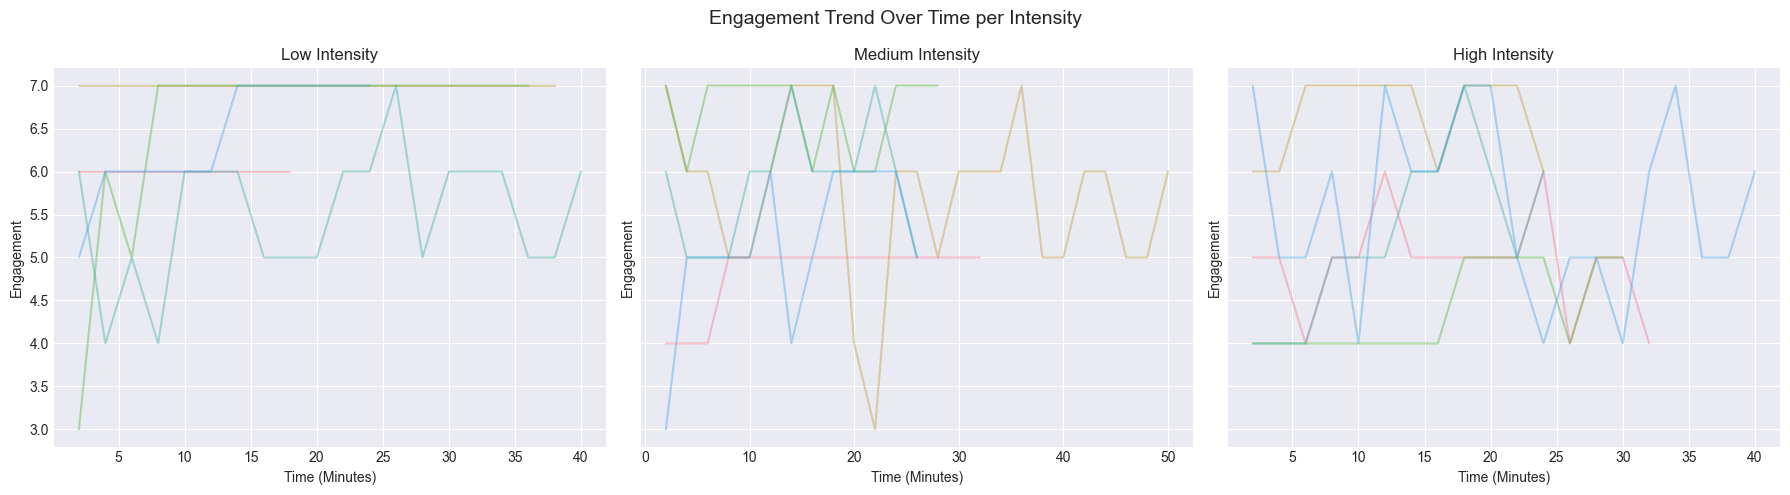

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

intensity_levels = [1, 2, 3]
intensity_names = {1: "Low", 2: "Medium", 3: "High"}

for i, intensity in enumerate(intensity_levels):
    
    df_filtered = merged_data[
        merged_data["AttackIntensity"] == intensity
    ]
    
    # Plot each participant
    for pid in df_filtered["ParticipantID"].unique():
        sub = df_filtered[df_filtered["ParticipantID"] == pid]
        sub = sub.sort_values("TimeMinutes")
        
        axes[i].plot(
            sub["TimeMinutes"],
            sub["Engagement"],
            alpha=0.4
        )
    
    axes[i].set_title(f"{intensity_names[intensity]} Intensity")
    axes[i].set_xlabel("Time (Minutes)")
    axes[i].set_ylabel("Engagement")

plt.suptitle("Engagement Trend Over Time per Intensity", fontsize=14)
plt.tight_layout()
plt.show()


## 4. Exploratory Data Analysis

### 4.1 Distribution of Dependent Variables

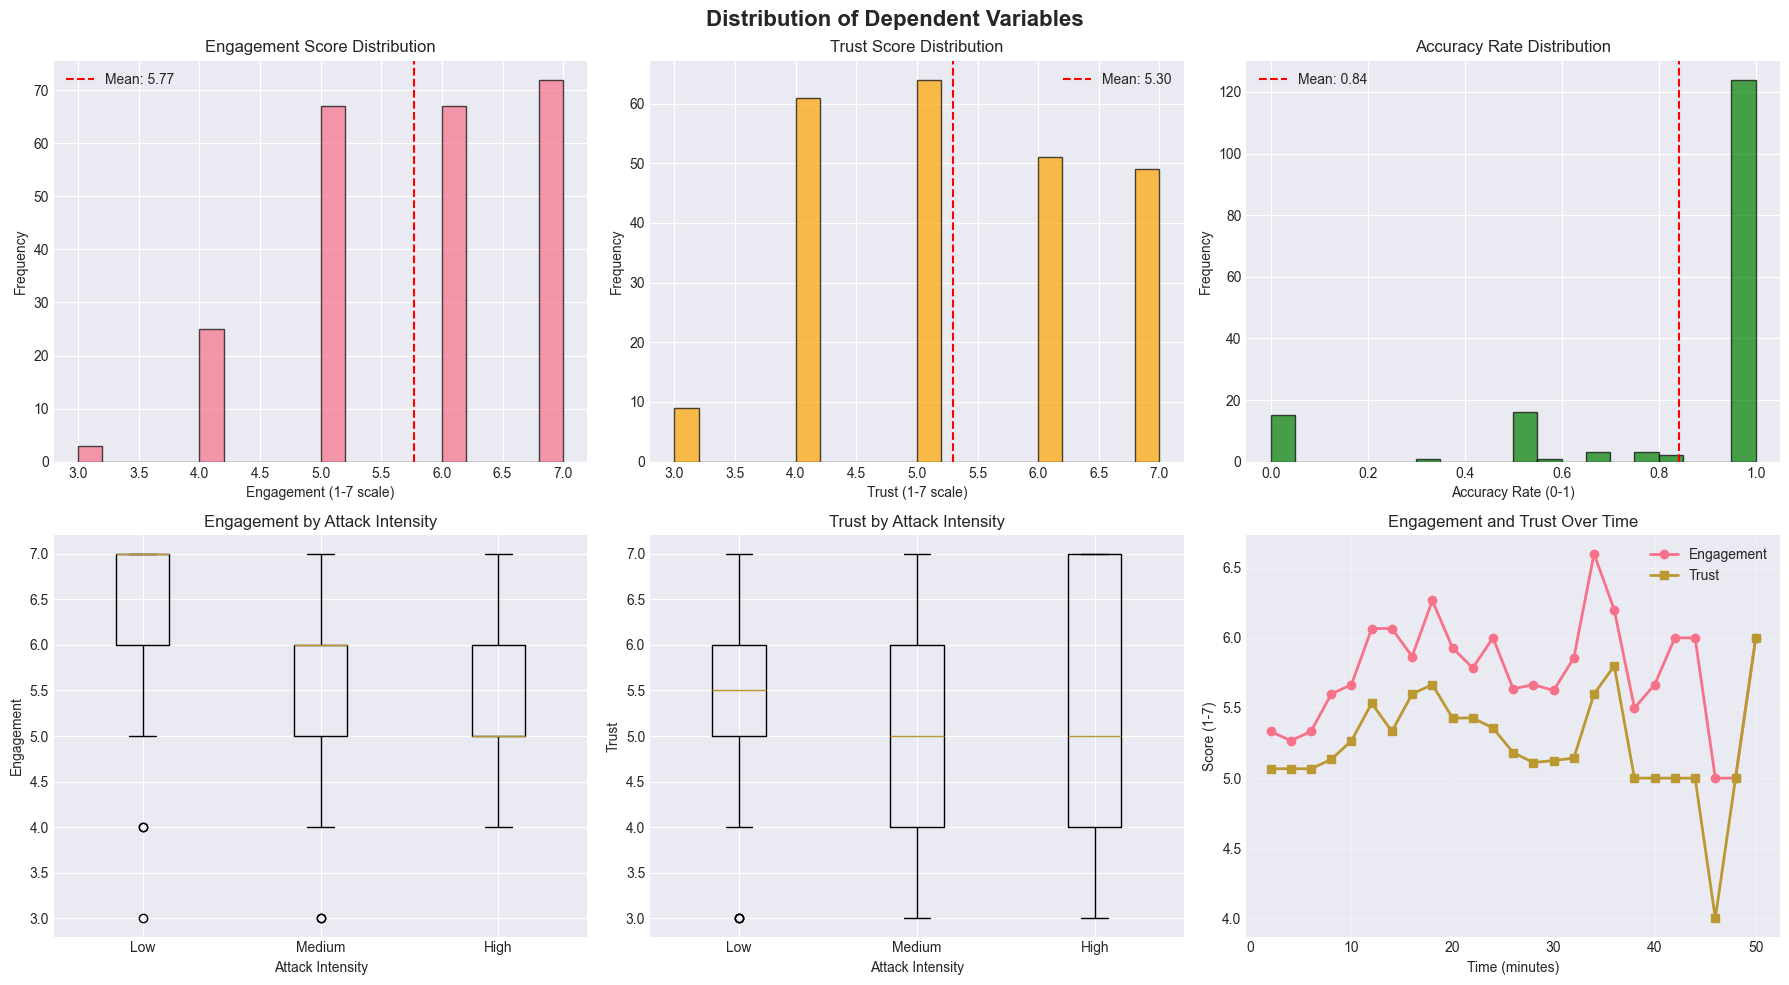


Descriptive Statistics for Dependent Variables:
       Engagement       Trust
count  234.000000  234.000000
mean     5.769231    5.299145
std      1.043143    1.177507
min      3.000000    3.000000
25%      5.000000    4.000000
50%      6.000000    5.000000
75%      7.000000    6.000000
max      7.000000    7.000000

Performance Metrics:
       AccuracyRate  AvgAttempts  AvgActivityDuration
count    165.000000   165.000000           165.000000
mean       0.841111     1.610000            48.391306
std        0.312735     0.883918            52.687798
min        0.000000     1.000000             1.873073
25%        1.000000     1.000000            17.120745
50%        1.000000     1.000000            32.998777
75%        1.000000     2.000000            56.331087
max        1.000000     4.000000           305.658807


In [15]:
# Visualize dependent variables distributions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Distribution of Dependent Variables', fontsize=16, fontweight='bold')

# Engagement distribution
axes[0, 0].hist(merged_data['Engagement'].dropna(), bins=20, edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Engagement Score Distribution')
axes[0, 0].set_xlabel('Engagement (1-7 scale)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].axvline(merged_data['Engagement'].mean(), color='red', linestyle='--', label=f"Mean: {merged_data['Engagement'].mean():.2f}")
axes[0, 0].legend()

# Trust distribution
axes[0, 1].hist(merged_data['Trust'].dropna(), bins=20, edgecolor='black', alpha=0.7, color='orange')
axes[0, 1].set_title('Trust Score Distribution')
axes[0, 1].set_xlabel('Trust (1-7 scale)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].axvline(merged_data['Trust'].mean(), color='red', linestyle='--', label=f"Mean: {merged_data['Trust'].mean():.2f}")
axes[0, 1].legend()

# Accuracy distribution (if available)
if 'AccuracyRate' in merged_data.columns:
    axes[0, 2].hist(merged_data['AccuracyRate'].dropna(), bins=20, edgecolor='black', alpha=0.7, color='green')
    axes[0, 2].set_title('Accuracy Rate Distribution')
    axes[0, 2].set_xlabel('Accuracy Rate (0-1)')
    axes[0, 2].set_ylabel('Frequency')
    axes[0, 2].axvline(merged_data['AccuracyRate'].mean(), color='red', linestyle='--', label=f"Mean: {merged_data['AccuracyRate'].mean():.2f}")
    axes[0, 2].legend()
else:
    axes[0, 2].text(0.5, 0.5, 'No Performance Data', ha='center', va='center')
    axes[0, 2].axis('off')

# Box plots by intensity
axes[1, 0].boxplot([merged_data[merged_data['Intensity'] == i]['Engagement'].dropna() for i in ['Low', 'Medium', 'High']], 
                    labels=['Low', 'Medium', 'High'])
axes[1, 0].set_title('Engagement by Attack Intensity')
axes[1, 0].set_xlabel('Attack Intensity')
axes[1, 0].set_ylabel('Engagement')

axes[1, 1].boxplot([merged_data[merged_data['Intensity'] == i]['Trust'].dropna() for i in ['Low', 'Medium', 'High']], 
                    labels=['Low', 'Medium', 'High'])
axes[1, 1].set_title('Trust by Attack Intensity')
axes[1, 1].set_xlabel('Attack Intensity')
axes[1, 1].set_ylabel('Trust')

# Time series of dependent variables
if 'TimeMinutes' in merged_data.columns:
    time_avg = merged_data.groupby('TimeMinutes')[['Engagement', 'Trust']].mean()
    axes[1, 2].plot(time_avg.index, time_avg['Engagement'], marker='o', label='Engagement', linewidth=2)
    axes[1, 2].plot(time_avg.index, time_avg['Trust'], marker='s', label='Trust', linewidth=2)
    axes[1, 2].set_title('Engagement and Trust Over Time')
    axes[1, 2].set_xlabel('Time (minutes)')
    axes[1, 2].set_ylabel('Score (1-7)')
    axes[1, 2].legend()
    axes[1, 2].grid(True, alpha=0.3)
else:
    axes[1, 2].axis('off')

plt.tight_layout()
plt.show()

# Print descriptive statistics
print("\nDescriptive Statistics for Dependent Variables:")
print(merged_data[['Engagement', 'Trust']].describe())

if 'AccuracyRate' in merged_data.columns:
    print("\nPerformance Metrics:")
    print(merged_data[['AccuracyRate', 'AvgAttempts', 'AvgActivityDuration']].describe())

### 4.2 Distribution of Independent Variables

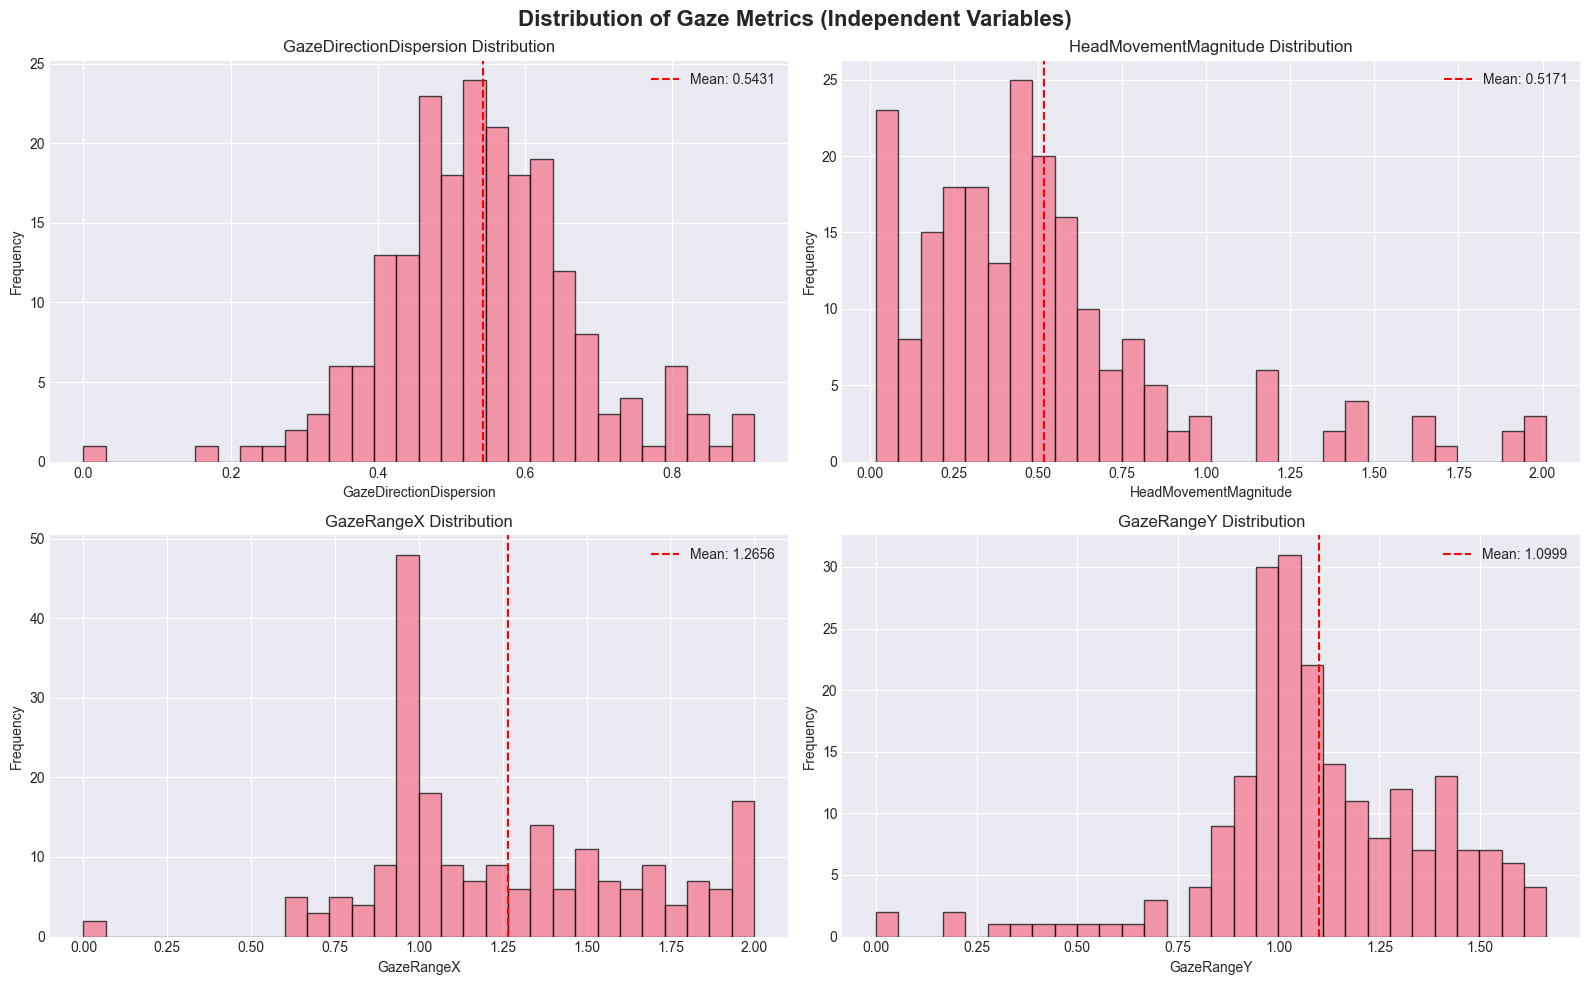


Gaze Metrics Descriptive Statistics:
       GazeDirectionDispersion  HeadMovementMagnitude  GazeRangeX  GazeRangeY
count               211.000000             211.000000  212.000000  212.000000
mean                  0.543118               0.517099    1.265560    1.099946
std                   0.132699               0.413939    0.395798    0.280985
min                   0.000000               0.017952    0.000000    0.000000
25%                   0.460745               0.264033    0.993128    0.983230
50%                   0.536846               0.445158    1.164990    1.070871
75%                   0.613037               0.629937    1.548281    1.279037
max                   0.911540               2.011803    1.999210    1.664606


In [16]:
# Visualize key gaze metrics
if 'GazeDirectionDispersion' in merged_data.columns:
    gaze_cols = ['GazeDirectionDispersion', 'HeadMovementMagnitude', 'GazeRangeX', 'GazeRangeY']
    available_gaze_cols = [col for col in gaze_cols if col in merged_data.columns]
    
    if len(available_gaze_cols) > 0:
        fig, axes = plt.subplots(2, 2, figsize=(16, 10))
        fig.suptitle('Distribution of Gaze Metrics (Independent Variables)', fontsize=16, fontweight='bold')
        
        for idx, col in enumerate(available_gaze_cols[:4]):
            row = idx // 2
            col_idx = idx % 2
            
            data = merged_data[col].dropna()
            axes[row, col_idx].hist(data, bins=30, edgecolor='black', alpha=0.7)
            axes[row, col_idx].set_title(f'{col} Distribution')
            axes[row, col_idx].set_xlabel(col)
            axes[row, col_idx].set_ylabel('Frequency')
            axes[row, col_idx].axvline(data.mean(), color='red', linestyle='--', 
                                      label=f'Mean: {data.mean():.4f}')
            axes[row, col_idx].legend()
        
        plt.tight_layout()
        plt.show()
        
        print("\nGaze Metrics Descriptive Statistics:")
        print(merged_data[available_gaze_cols].describe())
else:
    print("No gaze metrics available")

### 4.3 Distribution of System Metrics

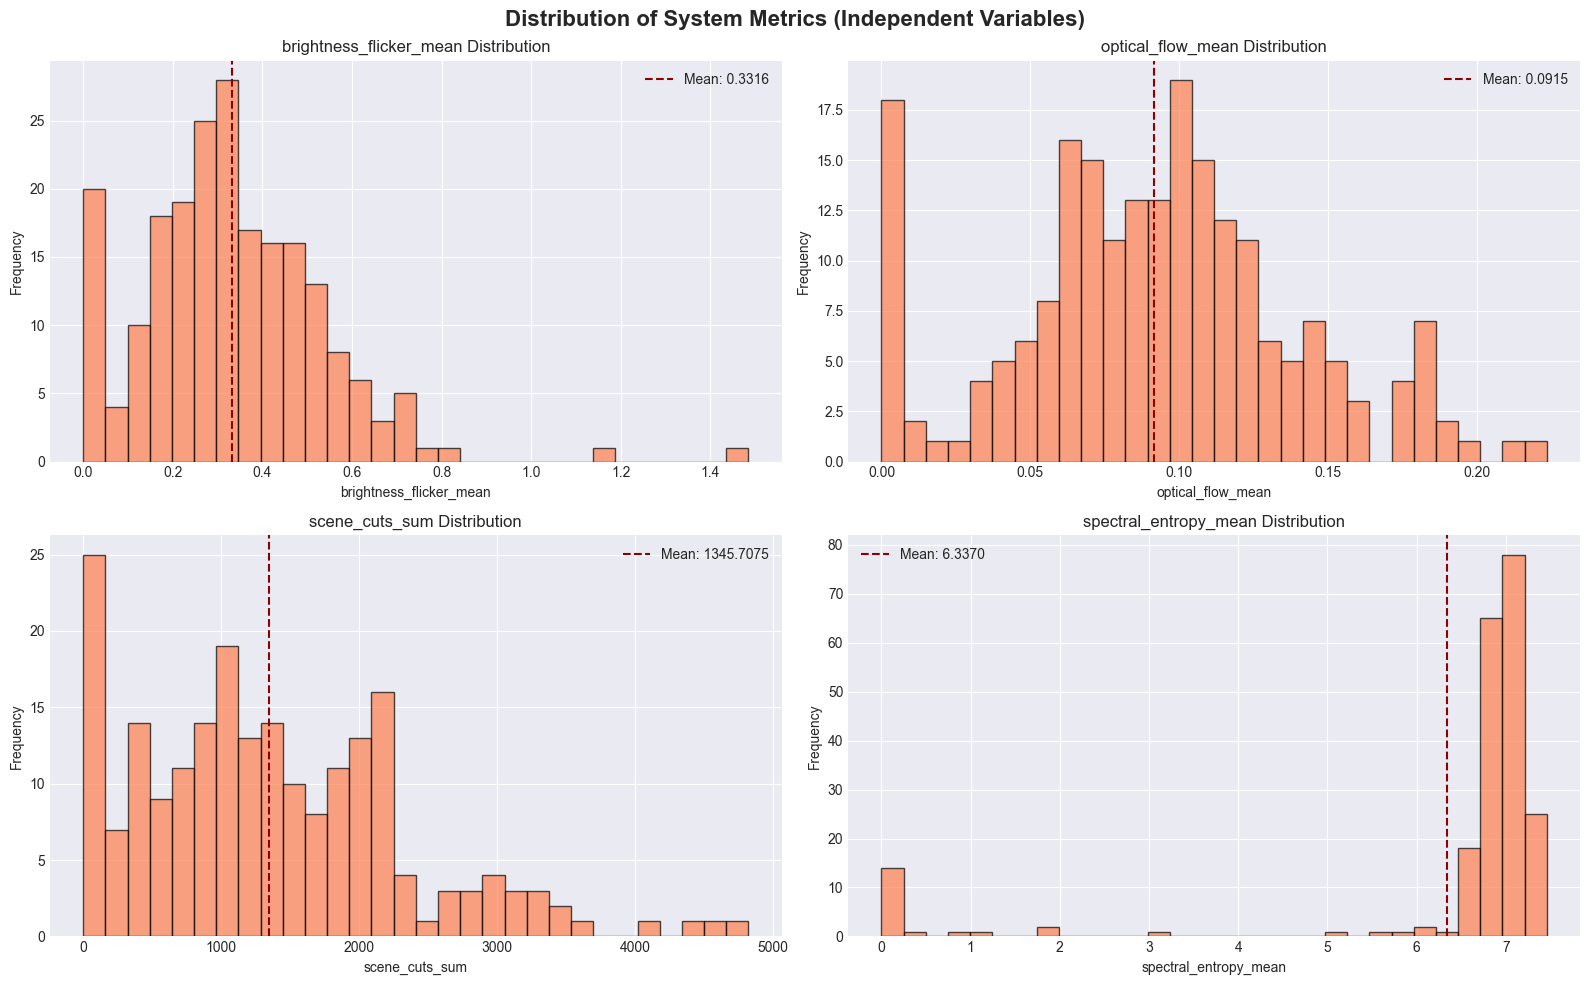


System Metrics Descriptive Statistics:
       brightness_flicker_mean  optical_flow_mean  scene_cuts_sum  spectral_entropy_mean
count               212.000000         212.000000      212.000000             212.000000
mean                  0.331560           0.091505     1345.707547               6.336978
std                   0.208164           0.047956      974.860199               1.940869
min                   0.000000           0.000000        0.000000               0.000000
25%                   0.201488           0.064607      616.250000               6.761746
50%                   0.316091           0.093253     1212.500000               6.954827
75%                   0.450961           0.118184     1977.750000               7.105618
max                   1.484895           0.223430     4823.000000               7.458638


In [17]:
# Visualize key system metrics
if 'brightness_flicker_mean' in merged_data.columns:
    system_cols = ['brightness_flicker_mean', 'optical_flow_mean', 'scene_cuts_sum', 'spectral_entropy_mean']
    available_system_cols = [col for col in system_cols if col in merged_data.columns]
    
    if len(available_system_cols) > 0:
        fig, axes = plt.subplots(2, 2, figsize=(16, 10))
        fig.suptitle('Distribution of System Metrics (Independent Variables)', fontsize=16, fontweight='bold')
        
        for idx, col in enumerate(available_system_cols[:4]):
            row = idx // 2
            col_idx = idx % 2
            
            data = merged_data[col].dropna()
            axes[row, col_idx].hist(data, bins=30, edgecolor='black', alpha=0.7, color='coral')
            axes[row, col_idx].set_title(f'{col} Distribution')
            axes[row, col_idx].set_xlabel(col)
            axes[row, col_idx].set_ylabel('Frequency')
            axes[row, col_idx].axvline(data.mean(), color='darkred', linestyle='--', 
                                      label=f'Mean: {data.mean():.4f}')
            axes[row, col_idx].legend()
        
        plt.tight_layout()
        plt.show()
        
        print("\nSystem Metrics Descriptive Statistics:")
        print(merged_data[available_system_cols].describe())
else:
    print("No system metrics available")

### 4.4 Normality Tests for Key Variables

In [18]:
# Test for normality using Shapiro-Wilk test
print("Normality Tests (Shapiro-Wilk):")
print("H0: Data is normally distributed")
print("If p < 0.05, reject H0 (data is NOT normally distributed)\n")

variables_to_test = ['Engagement', 'Trust', 'AttackIntensity']
if 'AccuracyRate' in merged_data.columns:
    variables_to_test.append('AccuracyRate')
if 'GazeDirectionDispersion' in merged_data.columns:
    variables_to_test.extend(['GazeDirectionDispersion', 'HeadMovementMagnitude'])
if 'brightness_flicker_mean' in merged_data.columns:
    variables_to_test.extend(['brightness_flicker_mean', 'optical_flow_mean'])

normality_results = []
for var in variables_to_test:
    if var in merged_data.columns:
        data = merged_data[var].dropna()
        if len(data) > 3:
            stat, p_value = shapiro(data)
            is_normal = 'Yes' if p_value > 0.05 else 'No'
            normality_results.append({
                'Variable': var,
                'Statistic': stat,
                'P-value': p_value,
                'Normal (p>0.05)': is_normal
            })

normality_df = pd.DataFrame(normality_results)
print(normality_df.to_string(index=False))

Normality Tests (Shapiro-Wilk):
H0: Data is normally distributed
If p < 0.05, reject H0 (data is NOT normally distributed)

               Variable  Statistic      P-value Normal (p>0.05)
             Engagement   0.872383 4.304104e-13              No
                  Trust   0.893414 8.282446e-12              No
        AttackIntensity   0.795973 8.666097e-17              No
           AccuracyRate   0.556312 2.314007e-20              No
GazeDirectionDispersion   0.978143 2.294496e-03              No
  HeadMovementMagnitude   0.848443 1.417207e-13              No
brightness_flicker_mean   0.932950 2.795705e-08              No
      optical_flow_mean   0.979943 4.066973e-03              No


## 5. Correlation Analysis

### 5.1 Select Features for Analysis

In [19]:
# Define dependent and independent variables for correlation analysis
dependent_vars = ['Engagement', 'Trust']
if 'AccuracyRate' in merged_data.columns:
    dependent_vars.append('AccuracyRate')

# Independent variables
independent_vars = ['AttackIntensity']

# Add gaze metrics
gaze_metrics = [
    'GazeDirectionDispersion', 'HeadMovementMagnitude', 
    'GazeRangeX', 'GazeRangeY', 'GazeRangeZ',
    'GazeDirectionX_mean', 'GazeDirectionY_mean', 'GazeDirectionZ_mean',
    'GazeDirectionX_std', 'GazeDirectionY_std', 'GazeDirectionZ_std'
]
independent_vars.extend([col for col in gaze_metrics if col in merged_data.columns])

# Add system metrics
system_metrics = [
    'brightness_flicker_mean', 'brightness_flicker_std', 'brightness_flicker_max',
    'optical_flow_mean', 'optical_flow_std', 'optical_flow_max',
    'scene_cuts_sum', 'spectral_entropy_mean', 'spatial_frequency_mean',
    'temporal_smoothness_mean', 'contrast_mean', 'edge_intensity_mean'
]
independent_vars.extend([col for col in system_metrics if col in merged_data.columns])

# Add performance metrics if available
if 'AvgAttempts' in merged_data.columns:
    independent_vars.extend(['AvgAttempts', 'AvgActivityDuration', 'TotalActivities'])

print(f"Dependent Variables ({len(dependent_vars)}): {dependent_vars}")
print(f"\nIndependent Variables ({len(independent_vars)}): {independent_vars[:10]}... (showing first 10)")

# Create analysis dataframe
analysis_data = merged_data[dependent_vars + independent_vars].copy()
print(f"\nAnalysis dataset shape: {analysis_data.shape}")
print(f"Missing values per variable:")
print(analysis_data.isnull().sum()[analysis_data.isnull().sum() > 0])

Dependent Variables (3): ['Engagement', 'Trust', 'AccuracyRate']

Independent Variables (27): ['AttackIntensity', 'GazeDirectionDispersion', 'HeadMovementMagnitude', 'GazeRangeX', 'GazeRangeY', 'GazeRangeZ', 'GazeDirectionX_mean', 'GazeDirectionY_mean', 'GazeDirectionZ_mean', 'GazeDirectionX_std']... (showing first 10)

Analysis dataset shape: (234, 30)
Missing values per variable:
AccuracyRate                69
GazeDirectionDispersion     23
HeadMovementMagnitude       23
GazeRangeX                  22
GazeRangeY                  22
GazeRangeZ                  22
GazeDirectionX_mean         22
GazeDirectionY_mean         22
GazeDirectionZ_mean         22
GazeDirectionX_std          23
GazeDirectionY_std          23
GazeDirectionZ_std          23
brightness_flicker_mean     22
brightness_flicker_std      23
brightness_flicker_max      22
optical_flow_mean           22
optical_flow_std            23
optical_flow_max            22
scene_cuts_sum              22
spectral_entropy_mean     

### 5.2 Pearson Correlation Analysis

In [20]:
# Calculate Pearson correlation coefficients
pearson_results = []
for dep_var in dependent_vars:
    for indep_var in independent_vars:
        valid_data = analysis_data[[dep_var, indep_var]].dropna()
        if len(valid_data) > 2:
            corr, p_value = pearsonr(valid_data[dep_var], valid_data[indep_var])
            pearson_results.append({
                'Dependent': dep_var,
                'Independent': indep_var,
                'Correlation': corr,
                'P-value': p_value,
                'Significant': 'Yes' if p_value < 0.05 else 'No',
                'N': len(valid_data)
            })

pearson_df = pd.DataFrame(pearson_results)

# Display significant correlations
print("PEARSON CORRELATION ANALYSIS")
print("="*80)
print("\nSignificant Correlations (p < 0.05):")
significant = pearson_df[pearson_df['Significant'] == 'Yes'].sort_values('P-value')
if len(significant) > 0:
    print(significant.to_string(index=False))
else:
    print("No significant correlations found")

print("\n\nTop 10 Strongest Correlations (by absolute value):")
top_corr = pearson_df.sort_values('Correlation', key=abs, ascending=False).head(10)
print(top_corr.to_string(index=False))

PEARSON CORRELATION ANALYSIS

Significant Correlations (p < 0.05):
   Dependent            Independent  Correlation      P-value Significant   N
  Engagement        AttackIntensity    -0.384360 1.176655e-09         Yes 234
  Engagement    GazeDirectionZ_mean     0.392059 3.356000e-09         Yes 212
  Engagement    edge_intensity_mean    -0.252655 2.012377e-04         Yes 212
  Engagement       optical_flow_std    -0.247314 2.860440e-04         Yes 211
  Engagement       optical_flow_max    -0.233030 6.259451e-04         Yes 212
  Engagement      optical_flow_mean    -0.227373 8.535490e-04         Yes 212
       Trust    GazeDirectionZ_mean     0.203575 2.903100e-03         Yes 212
       Trust spatial_frequency_mean    -0.181957 7.910333e-03         Yes 212
  Engagement spatial_frequency_mean    -0.178258 9.295330e-03         Yes 212
       Trust     GazeDirectionZ_std     0.177485 9.784621e-03         Yes 211
       Trust  spectral_entropy_mean    -0.176952 9.833299e-03         Yes 2

### 5.3 Spearman Correlation Analysis (Non-parametric)

## Why and How: Spearman Correlation Analysis

### Why Spearman Correlation?

In this analysis, we use Spearman’s rank correlation coefficient instead of Pearson correlation for several methodological reasons:

1. Non-Normal Distributions  
   Many behavioral and MR-related variables (e.g., engagement, gaze dispersion, head movement magnitude, attack intensity) may violate normality assumptions required by Pearson correlation.

2. Monotonic (Not Strictly Linear) Relationships  
   Spearman correlation detects monotonic relationships, even when they are not strictly linear. For example, engagement may consistently decrease as visual disruption increases, without forming a perfectly straight-line relationship.

3. Robustness to Outliers  
   Because Spearman operates on ranked data rather than raw values, it is less sensitive to extreme values and skewed distributions.

4. Appropriate for Behavioral and Likert-Scale Data  
   Engagement and trust measures are often ordinal or bounded (e.g., Likert scales), making rank-based correlation more appropriate.

---

### How the Analysis Works

1. Pairwise Iteration  
   For each dependent variable and independent variable pair:
   - Missing values are removed using dropna().
   - The sample size is checked to ensure N > 2.

2. Correlation Computation  
   Spearman correlation is computed using:
   
   corr, p_value = spearmanr(x, y)

   - corr: Spearman correlation coefficient (ρ)  
   - p_value: Statistical significance of the association  

3. Result Storage  
   For each variable pair, the following are stored:
   - Dependent variable  
   - Independent variable  
   - Correlation coefficient (ρ)  
   - P-value  
   - Significance flag (p < 0.05)  
   - Sample size (N)

4. Reporting  
   The script prints:
   - All statistically significant correlations (p < 0.05)  
   - The top 10 strongest correlations ranked by absolute correlation magnitude  

---

### Interpretation

- ρ > 0 indicates a positive monotonic relationship.  
- ρ < 0 indicates a negative monotonic relationship.  
- |ρ| closer to 1 indicates a stronger association.  
- p < 0.05 indicates statistical significance.

This analysis helps identify meaningful monotonic relationships between system features and behavioral outcomes, and provides a foundation for further regression or mediation modeling.


In [21]:
# Calculate Spearman correlation coefficients (better for non-normal distributions)
spearman_results = []
for dep_var in dependent_vars:
    for indep_var in independent_vars:
        valid_data = analysis_data[[dep_var, indep_var]].dropna()
        if len(valid_data) > 2:
            corr, p_value = spearmanr(valid_data[dep_var], valid_data[indep_var])
            spearman_results.append({
                'Dependent': dep_var,
                'Independent': indep_var,
                'Correlation': corr,
                'P-value': p_value,
                'Significant': 'Yes' if p_value < 0.05 else 'No',
                'N': len(valid_data)
            })

spearman_df = pd.DataFrame(spearman_results)

print("SPEARMAN CORRELATION ANALYSIS")
print("="*80)
print("\nSignificant Correlations (p < 0.05):")
significant_spearman = spearman_df[spearman_df['Significant'] == 'Yes'].sort_values('P-value')
if len(significant_spearman) > 0:
    print(significant_spearman.to_string(index=False))
else:
    print("No significant correlations found")

print("\n\nTop 10 Strongest Correlations (by absolute value):")
top_spearman = spearman_df.sort_values('Correlation', key=abs, ascending=False).head(10)
print(top_spearman.to_string(index=False))

SPEARMAN CORRELATION ANALYSIS

Significant Correlations (p < 0.05):
   Dependent             Independent  Correlation      P-value Significant   N
  Engagement         AttackIntensity    -0.396827 3.009511e-10         Yes 234
  Engagement     GazeDirectionZ_mean     0.388424 4.811379e-09         Yes 212
  Engagement     edge_intensity_mean    -0.273697 5.369963e-05         Yes 212
  Engagement        optical_flow_std    -0.227116 8.905887e-04         Yes 211
  Engagement        optical_flow_max    -0.222180 1.127303e-03         Yes 212
  Engagement       optical_flow_mean    -0.217773 1.420525e-03         Yes 212
AccuracyRate      GazeDirectionY_std     0.239901 1.911782e-03         Yes 165
       Trust     GazeDirectionZ_mean     0.208611 2.264681e-03         Yes 212
AccuracyRate              GazeRangeY     0.229884 2.974580e-03         Yes 165
  Engagement     GazeDirectionY_mean     0.173617 1.133425e-02         Yes 212
       Trust      GazeDirectionZ_std     0.169856 1.348756e-02 

### 5.4 Correlation Heatmaps

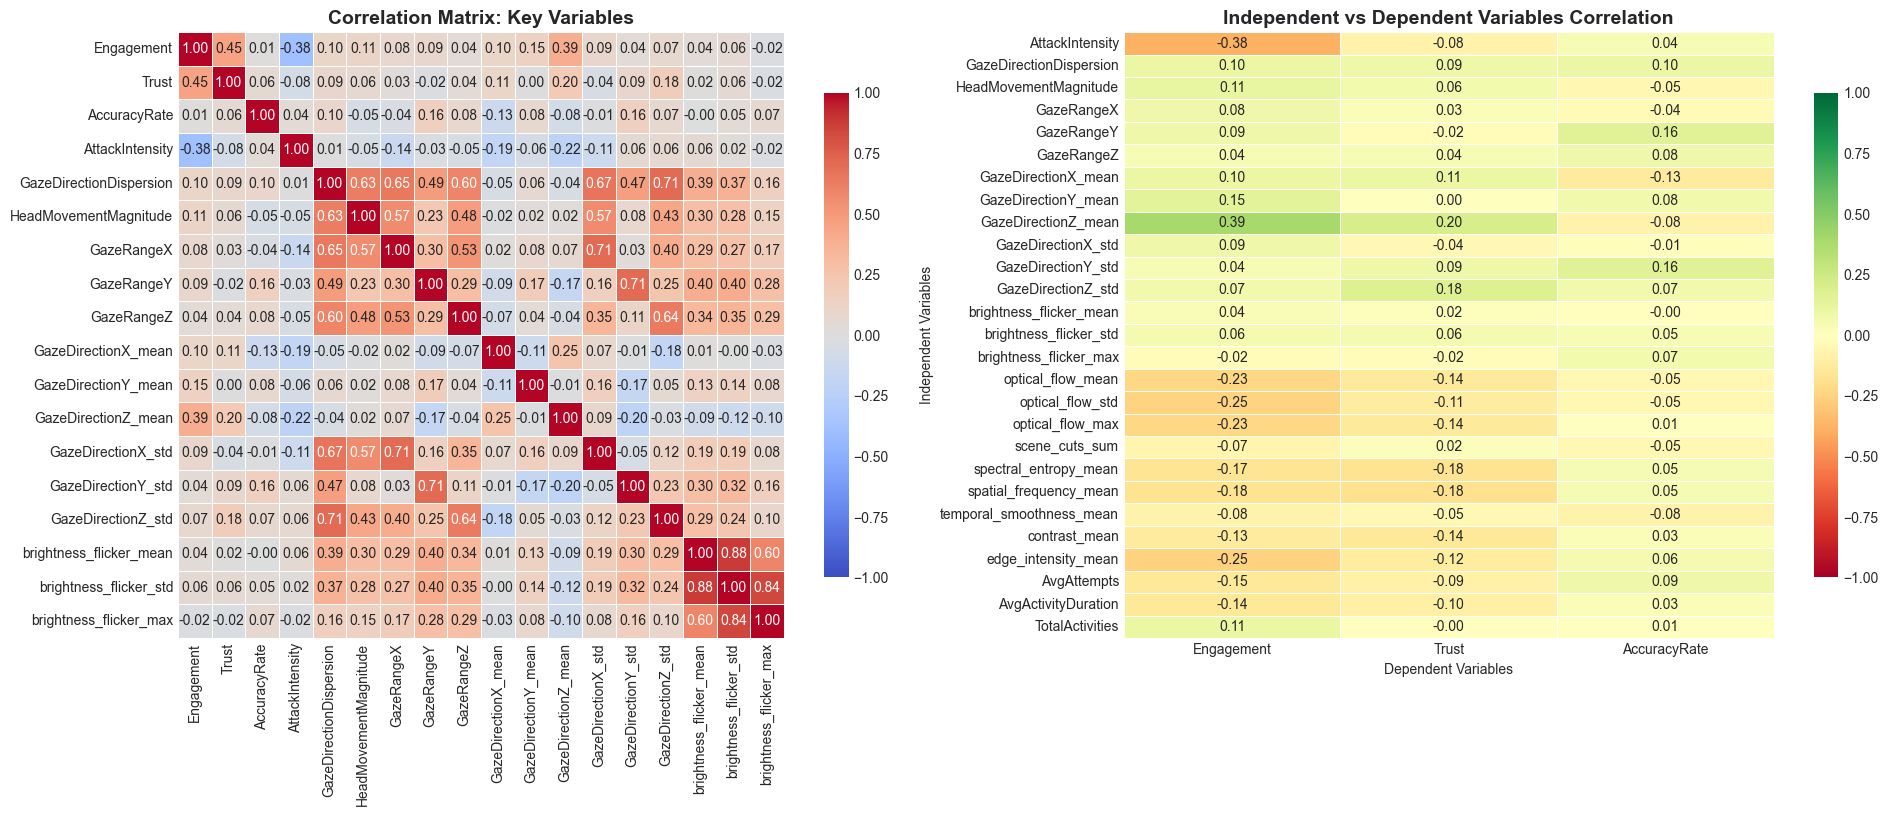

In [22]:
# Create correlation matrix for key variables
key_vars = dependent_vars + independent_vars[:min(15, len(independent_vars))]
correlation_matrix = analysis_data[key_vars].corr()

# Plot heatmap
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# Full correlation heatmap
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=axes[0],
            vmin=-1, vmax=1)
axes[0].set_title('Correlation Matrix: Key Variables', fontsize=14, fontweight='bold')

# Correlation of independent variables with dependent variables only
dep_indep_corr = analysis_data[dependent_vars + independent_vars].corr()
dep_indep_subset = dep_indep_corr.loc[independent_vars, dependent_vars]

sns.heatmap(dep_indep_subset, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=axes[1],
            vmin=-1, vmax=1)
axes[1].set_title('Independent vs Dependent Variables Correlation', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Dependent Variables')
axes[1].set_ylabel('Independent Variables')

plt.tight_layout()
plt.show()

## 6. Simple Linear Regression Models

### 6.1 Univariate Regression: Each Independent Variable Predicting Each Dependent Variable

In [23]:
# Simple linear regression for each pair
from scipy.stats import f

simple_regression_results = []

for dep_var in dependent_vars:
    print(f"\n{'='*80}")
    print(f"SIMPLE LINEAR REGRESSIONS FOR: {dep_var}")
    print(f"{'='*80}\n")
    
    for indep_var in independent_vars:
        # Prepare data
        valid_data = analysis_data[[dep_var, indep_var]].dropna()
        
        if len(valid_data) < 3:
            continue
        
        X = valid_data[[indep_var]].values
        y = valid_data[dep_var].values
        
        # Fit model
        model = LinearRegression()
        model.fit(X, y)
        
        # Predictions
        y_pred = model.predict(X)
        
        # Calculate metrics
        r2 = r2_score(y, y_pred)
        rmse = np.sqrt(mean_squared_error(y, y_pred))
        mae = mean_absolute_error(y, y_pred)
        
        # Calculate p-value using F-test
        n = len(y)
        k = 1  # number of predictors
        
        # Calculate F-statistic
        ss_res = np.sum((y - y_pred) ** 2)
        ss_tot = np.sum((y - y.mean()) ** 2)
        
        if ss_tot > 0:
            f_stat = (ss_tot - ss_res) / k / (ss_res / (n - k - 1))
            p_value = 1 - f.cdf(f_stat, k, n - k - 1)
        else:
            p_value = 1.0
        
        simple_regression_results.append({
            'Dependent': dep_var,
            'Independent': indep_var,
            'Coefficient': model.coef_[0],
            'Intercept': model.intercept_,
            'R²': r2,
            'RMSE': rmse,
            'MAE': mae,
            'P-value': p_value,
            'Significant': 'Yes' if p_value < 0.05 else 'No',
            'N': len(valid_data)
        })

# Convert to DataFrame
simple_reg_df = pd.DataFrame(simple_regression_results)

# Display significant models
print("\n" + "="*80)
print("SIGNIFICANT SIMPLE LINEAR REGRESSION MODELS (p < 0.05)")
print("="*80)
significant_models = simple_reg_df[simple_reg_df['Significant'] == 'Yes'].sort_values('R²', ascending=False)
if len(significant_models) > 0:
    print(significant_models.to_string(index=False))
else:
    print("No significant models found")

print("\n" + "="*80)
print("TOP 10 MODELS BY R² (Regardless of Significance)")
print("="*80)
top_models = simple_reg_df.sort_values('R²', ascending=False).head(10)
print(top_models.to_string(index=False))


SIMPLE LINEAR REGRESSIONS FOR: Engagement


SIMPLE LINEAR REGRESSIONS FOR: Trust


SIMPLE LINEAR REGRESSIONS FOR: AccuracyRate


SIGNIFICANT SIMPLE LINEAR REGRESSION MODELS (p < 0.05)
   Dependent            Independent  Coefficient  Intercept       R²     RMSE      MAE      P-value Significant   N
  Engagement    GazeDirectionZ_mean     0.852325   5.717430 0.153710 0.959720 0.785513 3.356000e-09         Yes 212
  Engagement        AttackIntensity    -0.494845   6.752577 0.147733 0.960952 0.795665 1.176655e-09         Yes 234
  Engagement    edge_intensity_mean    -0.043870   6.244059 0.063835 1.009396 0.848850 2.012377e-04         Yes 212
  Engagement       optical_flow_std    -7.788855   6.387800 0.061164 1.011954 0.850714 2.860440e-04         Yes 211
  Engagement       optical_flow_max    -1.446077   6.415694 0.054303 1.014521 0.857615 6.259451e-04         Yes 212
  Engagement      optical_flow_mean    -4.957982   6.213116 0.051699 1.015917 0.852836 8.535490e-04         Yes 212
   

### 6.2 Visualize Top Regression Relationships

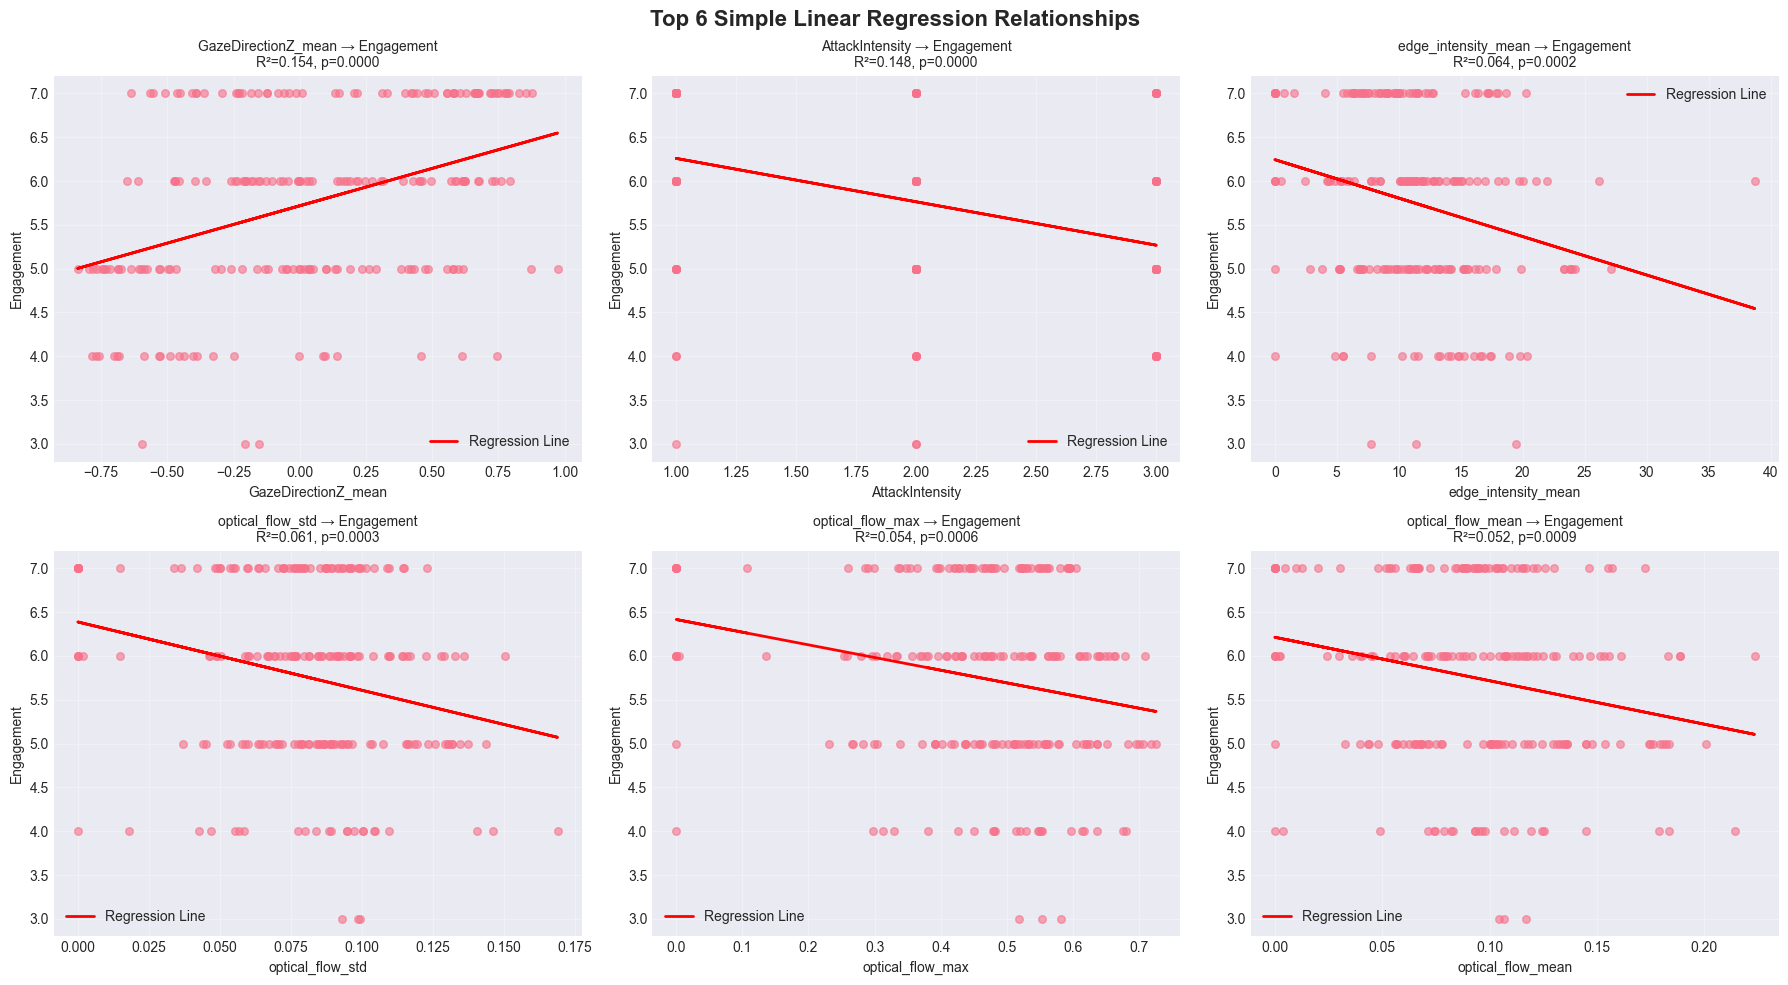

In [24]:
# Plot top 6 regression relationships
top_6_models = simple_reg_df.sort_values('R²', ascending=False).head(6)

if len(top_6_models) > 0:
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    fig.suptitle('Top 6 Simple Linear Regression Relationships', fontsize=16, fontweight='bold')
    
    for idx, (row_idx, row) in enumerate(top_6_models.iterrows()):
        ax_row = idx // 3
        ax_col = idx % 3
        
        dep_var = row['Dependent']
        indep_var = row['Independent']
        
        # Get data
        valid_data = analysis_data[[dep_var, indep_var]].dropna()
        X = valid_data[indep_var].values
        y = valid_data[dep_var].values
        
        # Fit model
        model = LinearRegression()
        model.fit(X.reshape(-1, 1), y)
        y_pred = model.predict(X.reshape(-1, 1))
        
        # Plot
        axes[ax_row, ax_col].scatter(X, y, alpha=0.6, s=30)
        axes[ax_row, ax_col].plot(X, y_pred, color='red', linewidth=2, label='Regression Line')
        axes[ax_row, ax_col].set_xlabel(indep_var, fontsize=10)
        axes[ax_row, ax_col].set_ylabel(dep_var, fontsize=10)
        axes[ax_row, ax_col].set_title(f"{indep_var} → {dep_var}\nR²={row['R²']:.3f}, p={row['P-value']:.4f}", 
                                      fontsize=10)
        axes[ax_row, ax_col].legend()
        axes[ax_row, ax_col].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
else:
    print("No regression models available for visualization")

## 7. Multiple Regression Models
To examine the combined effects of gaze and system features on each dependent variable, we conducted multiple linear regression analyses using a correlation-guided predictor selection strategy.

For each dependent variable, predictors were ranked based on the absolute value of their Pearson correlation coefficients. The top predictors (default: 10) were selected to reduce dimensionality while retaining variables with the strongest bivariate associations.

Only predictors available in the dataset were included. Rows containing missing values were removed prior to model fitting.

All predictors were standardized (z-scored) before regression to ensure comparability of coefficients and improve numerical stability. Models were estimated using Ordinary Least Squares (OLS).

For each model, we report:
- R² and Adjusted R²
- F-statistic and corresponding p-value
- Standardized regression coefficients
- Approximate coefficient significance using t-tests

This structured approach enables multivariate evaluation while maintaining interpretability and statistical rigor.

### 7.1 Prepare Data for Multiple Regression

In [25]:
# Select key predictors based on correlation analysis
# Choose top predictors for each dependent variable

def select_top_predictors(dep_var, correlation_df, n_top=5):
    """Select top n predictors based on correlation strength"""
    var_corr = correlation_df[correlation_df['Dependent'] == dep_var].copy()
    var_corr['AbsCorr'] = var_corr['Correlation'].abs()
    top_pred = var_corr.nlargest(n_top, 'AbsCorr')['Independent'].tolist()
    return top_pred

# Build multiple regression for each dependent variable
multiple_regression_results = {}

for dep_var in dependent_vars:
    print(f"\n{'='*80}")
    print(f"MULTIPLE REGRESSION FOR: {dep_var}")
    print(f"{'='*80}\n")
    
    # Get top predictors
    top_predictors = select_top_predictors(dep_var, pearson_df, n_top=10)
    
    # Filter to only available columns
    available_predictors = [p for p in top_predictors if p in analysis_data.columns]
    
    if len(available_predictors) == 0:
        print(f"No predictors available for {dep_var}")
        continue
    
    # Prepare data
    model_data = analysis_data[[dep_var] + available_predictors].dropna()
    
    if len(model_data) < 3:
        print(f"Insufficient data for {dep_var} (N={len(model_data)})")
        continue
    
    X = model_data[available_predictors]
    y = model_data[dep_var]
    
    print(f"Model data: N={len(model_data)}, Predictors={len(available_predictors)}")
    print(f"Predictors: {available_predictors}\n")
    
    # Standardize features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Fit model using sklearn
    lr_model = LinearRegression()
    lr_model.fit(X_scaled, y)
    
    # Calculate predictions and metrics
    y_pred = lr_model.predict(X_scaled)
    r2 = r2_score(y, y_pred)
    
    # Calculate adjusted R²
    n = len(y)
    k = len(available_predictors)
    adj_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
    
    # Calculate F-statistic
    ss_res = np.sum((y - y_pred) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    f_stat = ((ss_tot - ss_res) / k) / (ss_res / (n - k - 1))
    f_pvalue = 1 - f.cdf(f_stat, k, n - k - 1)
    
    # Calculate p-values for coefficients (approximation using t-distribution)
    mse = ss_res / (n - k - 1)
    var_b = mse * np.linalg.inv(X_scaled.T @ X_scaled).diagonal()
    se_b = np.sqrt(var_b)
    t_b = lr_model.coef_ / se_b
    p_values = 2 * (1 - stats.t.cdf(np.abs(t_b), n - k - 1))
    
    # Store results
    multiple_regression_results[dep_var] = {
        'model': lr_model,
        'predictors': available_predictors,
        'scaler': scaler,
        'n_observations': len(model_data),
        'r2': r2,
        'adj_r2': adj_r2,
        'f_stat': f_stat,
        'f_pvalue': f_pvalue,
        'coef': lr_model.coef_,
        'intercept': lr_model.intercept_,
        'p_values': p_values
    }
    
    # Print summary
    print(f"R²: {r2:.4f}")
    print(f"Adjusted R²: {adj_r2:.4f}")
    print(f"F-statistic: {f_stat:.4f}, p-value: {f_pvalue:.4f}")
    print(f"\nCoefficients:")
    print(f"  Intercept: {lr_model.intercept_:.4f}")
    for i, pred in enumerate(available_predictors):
        sig = "***" if p_values[i] < 0.001 else "**" if p_values[i] < 0.01 else "*" if p_values[i] < 0.05 else ""
        print(f"  {pred}: {lr_model.coef_[i]:.4f} (p={p_values[i]:.4f}) {sig}")
    print("\n")


MULTIPLE REGRESSION FOR: Engagement

Model data: N=165, Predictors=10
Predictors: ['GazeDirectionZ_mean', 'AttackIntensity', 'edge_intensity_mean', 'optical_flow_std', 'optical_flow_max', 'optical_flow_mean', 'spatial_frequency_mean', 'spectral_entropy_mean', 'AvgAttempts', 'GazeDirectionY_mean']

R²: 0.2759
Adjusted R²: 0.2288
F-statistic: 5.8667, p-value: 0.0000

Coefficients:
  Intercept: 5.8061
  GazeDirectionZ_mean: 0.3757 (p=0.0000) ***
  AttackIntensity: -0.1454 (p=0.1122) 
  edge_intensity_mean: -0.1719 (p=0.1940) 
  optical_flow_std: 0.0210 (p=0.9218) 
  optical_flow_max: -0.0189 (p=0.9245) 
  optical_flow_mean: -0.2336 (p=0.0951) 
  spatial_frequency_mean: -0.3594 (p=0.6608) 
  spectral_entropy_mean: 0.5359 (p=0.5300) 
  AvgAttempts: -0.1175 (p=0.1353) 
  GazeDirectionY_mean: 0.0540 (p=0.5251) 



MULTIPLE REGRESSION FOR: Trust

Model data: N=211, Predictors=10
Predictors: ['GazeDirectionZ_mean', 'spatial_frequency_mean', 'GazeDirectionZ_std', 'spectral_entropy_mean', 'contr

### 7.2 Check for Multicollinearity (VIF)

To ensure the validity of multiple regression estimates, we assessed 
multicollinearity among predictors using Variance Inflation Factors (VIF). 
VIF values greater than 10 indicate problematic multicollinearity.

In [26]:
# Calculate VIF for each model
print("VARIANCE INFLATION FACTOR (VIF) ANALYSIS")
print("VIF > 10 indicates high multicollinearity")
print("="*80)

try:
    from statsmodels.stats.outliers_influence import variance_inflation_factor as vif_calc
    vif_available = True
except:
    vif_available = False
    print("Note: VIF calculation unavailable due to statsmodels compatibility issue")

if vif_available:
    for dep_var, results in multiple_regression_results.items():
        print(f"\n{dep_var}:")
        print("-" * 40)
        
        predictors = results['predictors']
        model_data = analysis_data[[dep_var] + predictors].dropna()
        X = model_data[predictors]
        
        # Calculate VIF
        vif_data = pd.DataFrame()
        vif_data['Predictor'] = predictors
        vif_data['VIF'] = [vif_calc(X.values, i) for i in range(len(predictors))]
        vif_data = vif_data.sort_values('VIF', ascending=False)
        
        print(vif_data.to_string(index=False))
        
        # Flag high multicollinearity
        high_vif = vif_data[vif_data['VIF'] > 10]
        if len(high_vif) > 0:
            print(f"\nWARNING: {len(high_vif)} predictors have VIF > 10 (high multicollinearity)")
else:
    print("\nUsing correlation-based multicollinearity check instead:")
    for dep_var, results in multiple_regression_results.items():
        print(f"\n{dep_var}:")
        print("-" * 40)
        
        predictors = results['predictors']
        model_data = analysis_data[predictors].dropna()
        
        # Calculate correlation matrix
        corr_matrix = model_data.corr()
        
        # Find high correlations
        high_corr_pairs = []
        for i in range(len(predictors)):
            for j in range(i+1, len(predictors)):
                if abs(corr_matrix.iloc[i, j]) > 0.7:
                    high_corr_pairs.append((predictors[i], predictors[j], corr_matrix.iloc[i, j]))
        
        if high_corr_pairs:
            print("High correlations between predictors (|r| > 0.7):")
            for p1, p2, corr in high_corr_pairs:
                print(f"  {p1} <-> {p2}: {corr:.3f}")
        else:
            print("No high correlations detected (all |r| < 0.7)")

VARIANCE INFLATION FACTOR (VIF) ANALYSIS
VIF > 10 indicates high multicollinearity

Engagement:
----------------------------------------
             Predictor         VIF
 spectral_entropy_mean 1618.525665
spatial_frequency_mean 1562.110435
      optical_flow_max   70.952247
      optical_flow_std   65.711667
     optical_flow_mean   15.873456
   edge_intensity_mean   12.692961
       AttackIntensity    5.970426
           AvgAttempts    4.676886
   GazeDirectionY_mean    3.551127
   GazeDirectionZ_mean    1.163310


Trust:
----------------------------------------
             Predictor         VIF
 spectral_entropy_mean 3553.032545
spatial_frequency_mean 2025.035591
         contrast_mean  293.539405
      optical_flow_max   70.344670
      optical_flow_std   70.031979
     optical_flow_mean   16.375254
   edge_intensity_mean    9.745645
    GazeDirectionZ_std    6.068073
   GazeDirectionX_mean    1.278843
   GazeDirectionZ_mean    1.273131


AccuracyRate:
---------------------------

### 7.3 Model Diagnostics: Residual Analysis

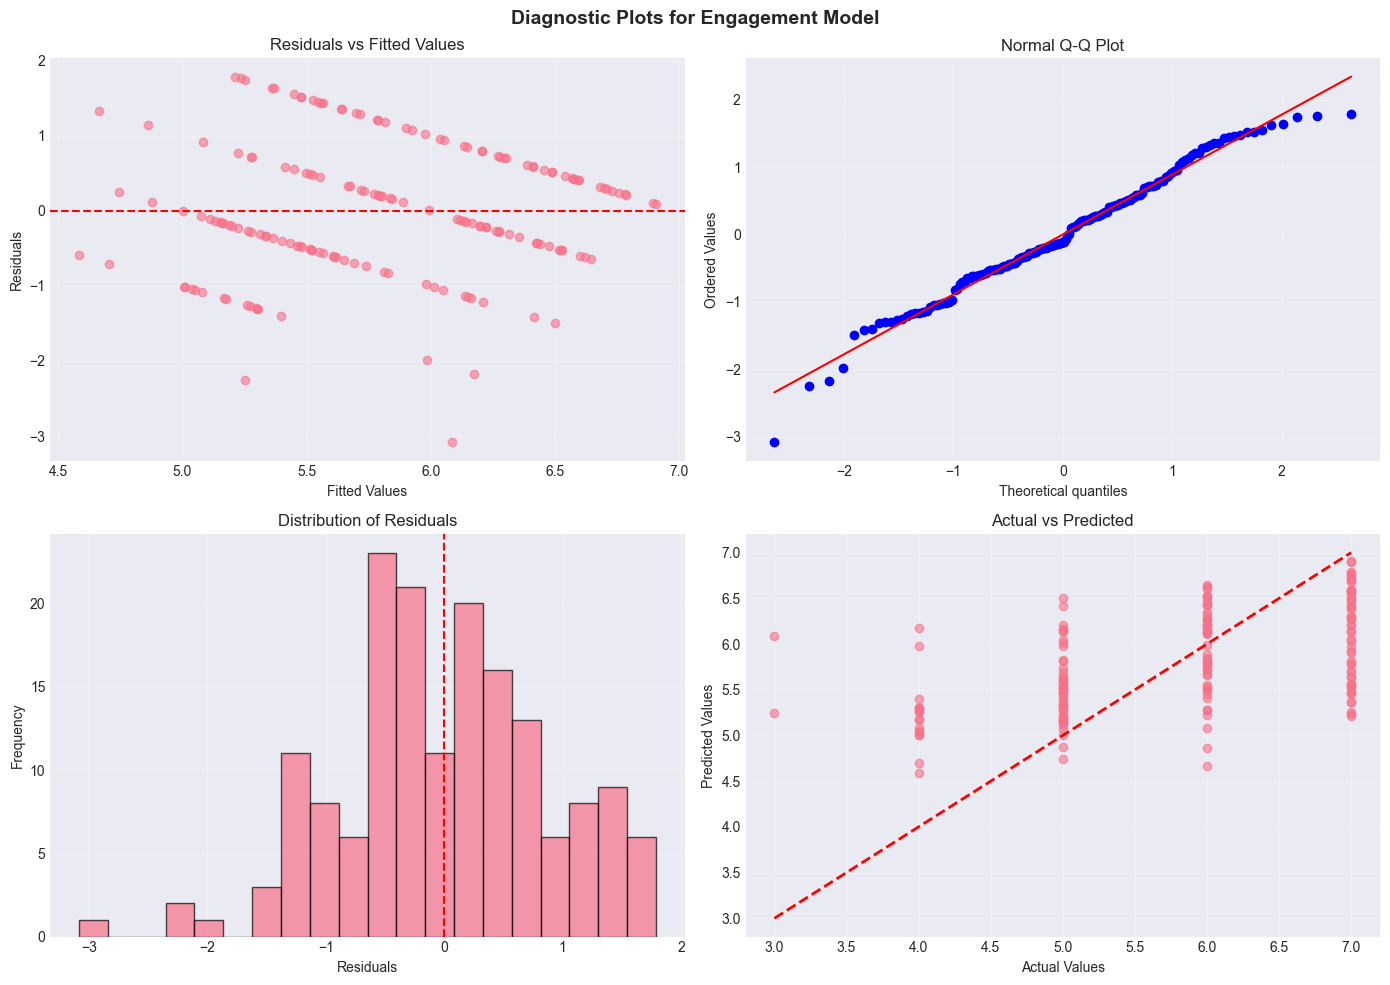


Engagement - Shapiro-Wilk test for residuals:
  Statistic: 0.9856, P-value: 0.0862
  Residuals are normally distributed



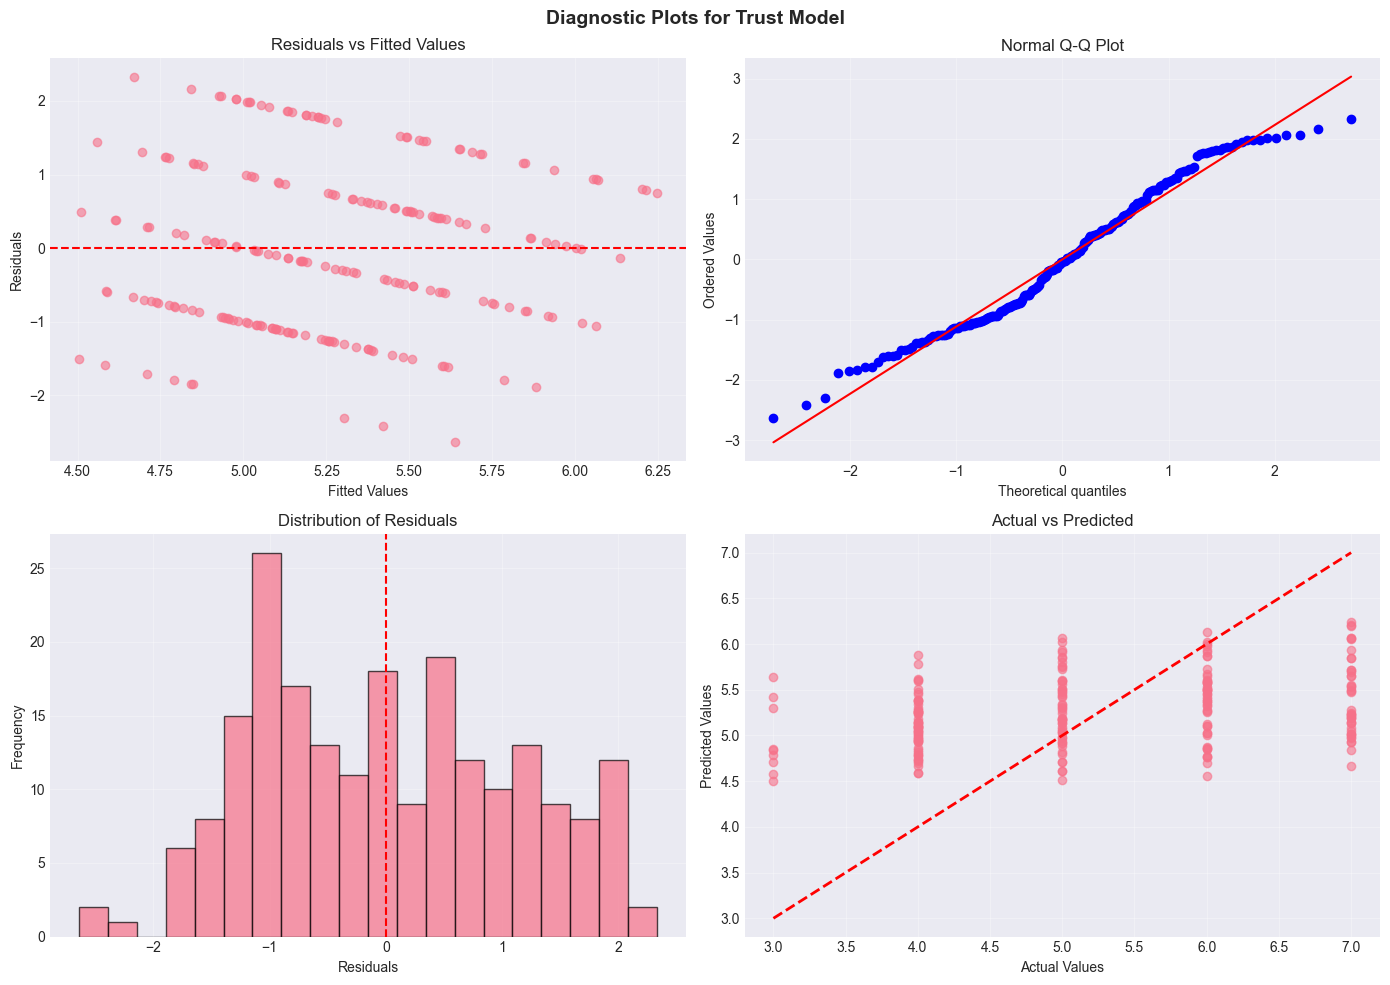


Trust - Shapiro-Wilk test for residuals:
  Statistic: 0.9731, P-value: 0.0005
  Residuals are NOT normally distributed



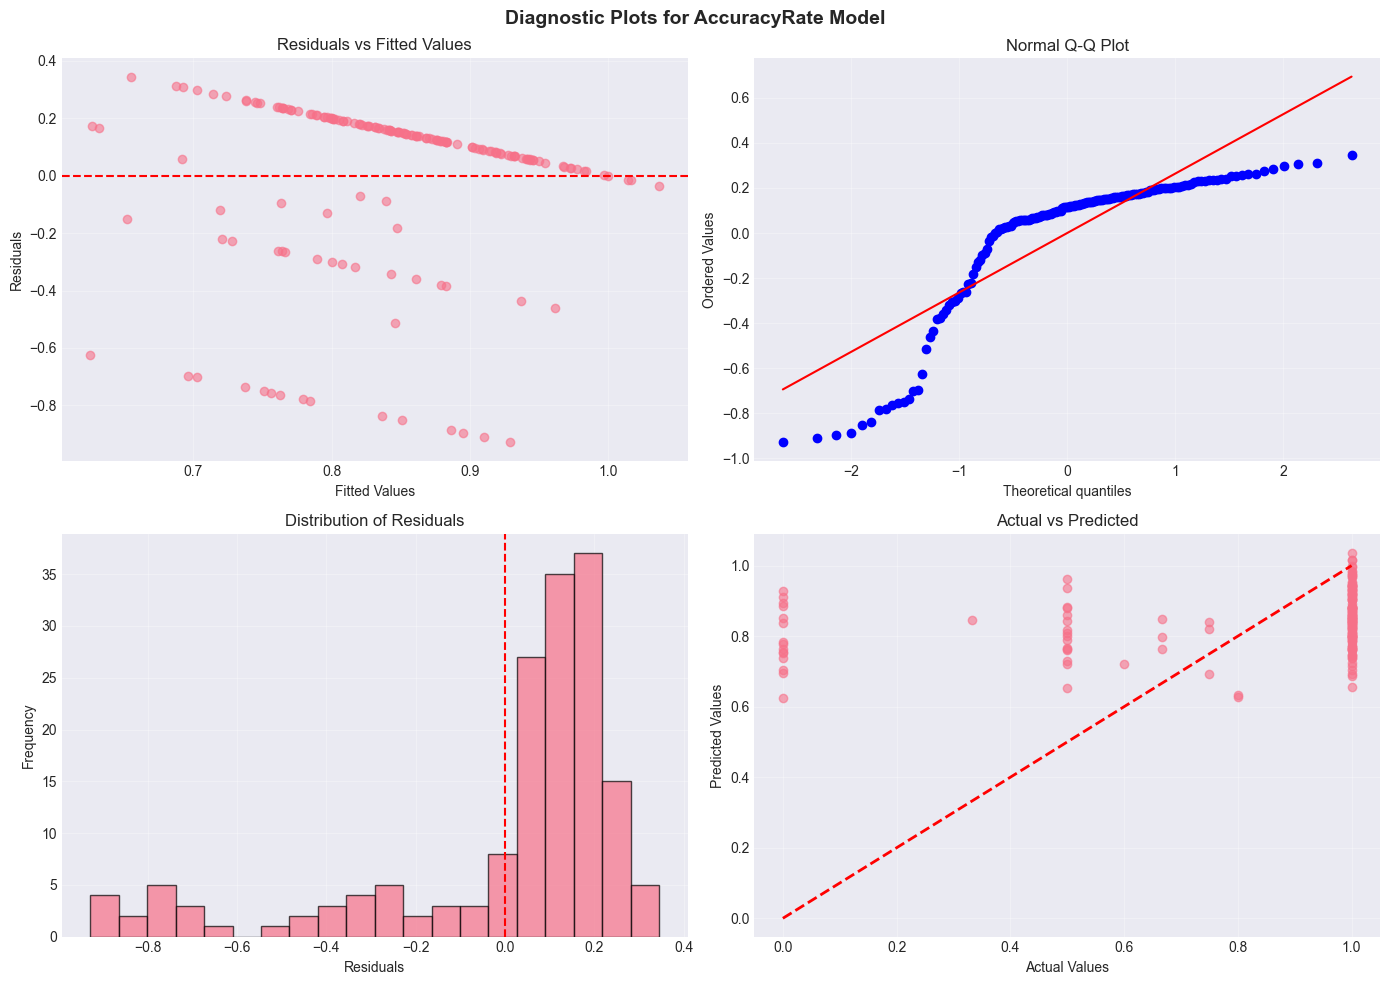


AccuracyRate - Shapiro-Wilk test for residuals:
  Statistic: 0.7476, P-value: 0.0000
  Residuals are NOT normally distributed



In [27]:
# Residual plots for each model
for dep_var, results in multiple_regression_results.items():
    model = results['model']
    predictors = results['predictors']
    
    # Get data
    model_data = analysis_data[[dep_var] + predictors].dropna()
    X = model_data[predictors]
    y = model_data[dep_var]
    
    # Scale and predict
    X_scaled = results['scaler'].transform(X)
    y_pred = model.predict(X_scaled)
    residuals = y.values - y_pred
    
    # Create diagnostic plots
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(f'Diagnostic Plots for {dep_var} Model', fontsize=14, fontweight='bold')
    
    # 1. Residuals vs Fitted
    axes[0, 0].scatter(y_pred, residuals, alpha=0.6)
    axes[0, 0].axhline(y=0, color='red', linestyle='--')
    axes[0, 0].set_xlabel('Fitted Values')
    axes[0, 0].set_ylabel('Residuals')
    axes[0, 0].set_title('Residuals vs Fitted Values')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Q-Q plot
    stats.probplot(residuals, dist="norm", plot=axes[0, 1])
    axes[0, 1].set_title('Normal Q-Q Plot')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Histogram of residuals
    axes[1, 0].hist(residuals, bins=20, edgecolor='black', alpha=0.7)
    axes[1, 0].axvline(x=0, color='red', linestyle='--')
    axes[1, 0].set_xlabel('Residuals')
    axes[1, 0].set_ylabel('Frequency')
    axes[1, 0].set_title('Distribution of Residuals')
    axes[1, 0].grid(True, alpha=0.3)
    
    # 4. Actual vs Predicted
    axes[1, 1].scatter(y.values, y_pred, alpha=0.6)
    axes[1, 1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
    axes[1, 1].set_xlabel('Actual Values')
    axes[1, 1].set_ylabel('Predicted Values')
    axes[1, 1].set_title('Actual vs Predicted')
    axes[1, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # Test residuals for normality
    stat, p_value = shapiro(residuals)
    print(f"\n{dep_var} - Shapiro-Wilk test for residuals:")
    print(f"  Statistic: {stat:.4f}, P-value: {p_value:.4f}")
    print(f"  Residuals are {'normally distributed' if p_value > 0.05 else 'NOT normally distributed'}")
    print()

## 8. Summary and Key Findings

### 8.1 Model Performance Summary

In [28]:
# Summarize multiple regression models
print("="*80)
print("MULTIPLE REGRESSION MODEL SUMMARY")
print("="*80)

summary_data = []
for dep_var, results in multiple_regression_results.items():
    summary_data.append({
        'Dependent Variable': dep_var,
        'R²': results['r2'],
        'Adjusted R²': results['adj_r2'],
        'F-statistic': results['f_stat'],
        'Prob (F-statistic)': results['f_pvalue'],
        'N Observations': results['n_observations'],
        'N Predictors': len(results['predictors'])
    })

summary_df = pd.DataFrame(summary_data)
print("\n", summary_df.to_string(index=False))

print("\n\n" + "="*80)
print("INTERPRETATION GUIDE")
print("="*80)
print("""
R²: Proportion of variance explained by the model (0-1, higher is better)
Adjusted R²: R² adjusted for number of predictors (accounts for model complexity)
F-statistic: Tests if model is significantly better than intercept-only model
Prob (F-statistic): P-value for F-test (< 0.05 indicates significant model)

Model Quality:
- R² < 0.3: Weak explanatory power
- R² 0.3-0.5: Moderate explanatory power
- R² > 0.5: Strong explanatory power
""")

MULTIPLE REGRESSION MODEL SUMMARY

 Dependent Variable       R²  Adjusted R²  F-statistic  Prob (F-statistic)  N Observations  N Predictors
        Engagement 0.275864     0.228842     5.866709        1.779645e-07             165            10
             Trust 0.109549     0.065027     2.460536        8.547370e-03             211            10
      AccuracyRate 0.072801     0.012594     1.209172        2.891585e-01             165            10


INTERPRETATION GUIDE

R²: Proportion of variance explained by the model (0-1, higher is better)
Adjusted R²: R² adjusted for number of predictors (accounts for model complexity)
F-statistic: Tests if model is significantly better than intercept-only model
Prob (F-statistic): P-value for F-test (< 0.05 indicates significant model)

Model Quality:
- R² < 0.3: Weak explanatory power
- R² 0.3-0.5: Moderate explanatory power
- R² > 0.5: Strong explanatory power



### 8.2 Key Findings by Dependent Variable

In [29]:
# Extract and display significant predictors for each dependent variable
print("="*80)
print("SIGNIFICANT PREDICTORS FOR EACH DEPENDENT VARIABLE")
print("="*80)

for dep_var, results in multiple_regression_results.items():
    model = results['model']
    predictors = results['predictors']
    
    print(f"\n{dep_var}:")
    print("-" * 60)
    
    # Get coefficients and p-values from stored results
    coefficients = [results['intercept']] + list(results['coef'])
    p_values = [0.0] + list(results['p_values'])  # Intercept p-value placeholder
    
    coef_df = pd.DataFrame({
        'Predictor': ['Intercept'] + predictors,
        'Coefficient': coefficients,
        'P-value': p_values,
        'Significant': ['Yes' if p < 0.05 else 'No' for p in p_values]
    })
    
    # Format p-values for display
    coef_df['P-value_formatted'] = coef_df['P-value'].apply(lambda p: f"{p:.4f}" if p >= 0.0001 else "< 0.0001")
    
    # Show significant predictors
    sig_predictors = coef_df[coef_df['Significant'] == 'Yes'][['Predictor', 'Coefficient', 'P-value_formatted', 'Significant']].copy()
    sig_predictors.rename(columns={'P-value_formatted': 'P-value'}, inplace=True)
    if len(sig_predictors) > 0:
        print("\nSignificant Predictors (p < 0.05):")
        print(sig_predictors.to_string(index=False))
    else:
        print("\nNo significant predictors found")
    
    # Model fit
    print(f"\nModel Fit:")
    print(f"  R² = {results['r2']:.4f}")
    print(f"  Adjusted R² = {results['adj_r2']:.4f}")
    p_str = f"{results['f_pvalue']:.4f}" if results['f_pvalue'] >= 0.0001 else "< 0.0001"
    print(f"  F-statistic = {results['f_stat']:.4f} (p = {p_str})")
    print()

SIGNIFICANT PREDICTORS FOR EACH DEPENDENT VARIABLE

Engagement:
------------------------------------------------------------

Significant Predictors (p < 0.05):
          Predictor  Coefficient  P-value Significant
          Intercept     5.806061 < 0.0001         Yes
GazeDirectionZ_mean     0.375688 < 0.0001         Yes

Model Fit:
  R² = 0.2759
  Adjusted R² = 0.2288
  F-statistic = 5.8667 (p = < 0.0001)


Trust:
------------------------------------------------------------

Significant Predictors (p < 0.05):
         Predictor  Coefficient  P-value Significant
         Intercept     5.274882 < 0.0001         Yes
GazeDirectionZ_std     0.251036   0.0040         Yes

Model Fit:
  R² = 0.1095
  Adjusted R² = 0.0650
  F-statistic = 2.4605 (p = 0.0085)


AccuracyRate:
------------------------------------------------------------

Significant Predictors (p < 0.05):
Predictor  Coefficient  P-value Significant
Intercept     0.841111 < 0.0001         Yes

Model Fit:
  R² = 0.0728
  Adjusted R²

### 8.3 Visualization: Predictor Importance

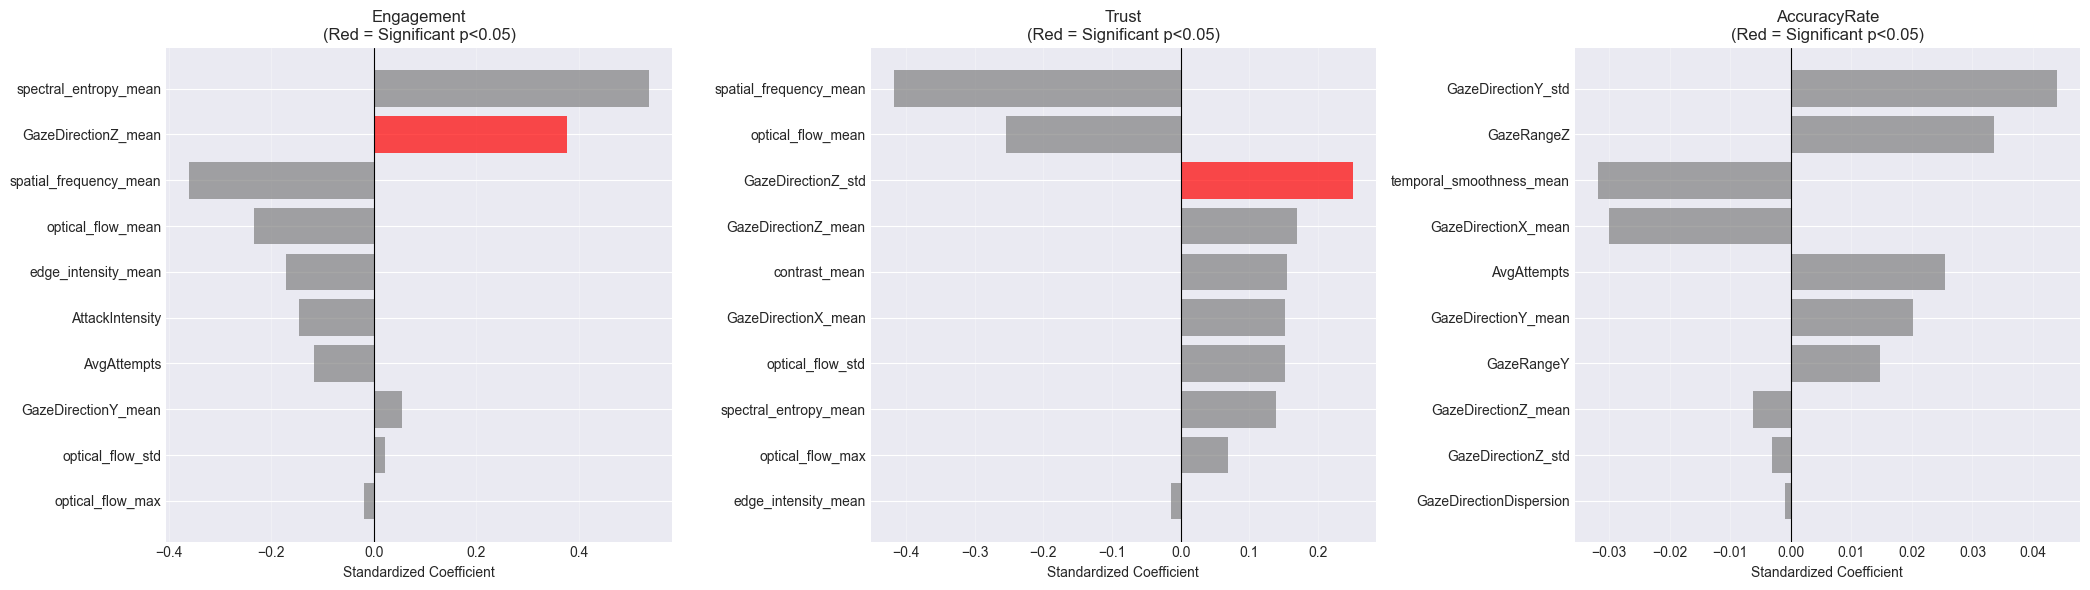

In [30]:
# Plot coefficient magnitudes for significant predictors
n_models = len(multiple_regression_results)
if n_models > 0:
    fig, axes = plt.subplots(1, n_models, figsize=(7*n_models, 6))
    if n_models == 1:
        axes = [axes]
    
    for idx, (dep_var, results) in enumerate(multiple_regression_results.items()):
        predictors = results['predictors']
        
        # Get coefficients (excluding intercept)
        coefs = results['coef']
        p_values = results['p_values']
        
        # Create DataFrame
        coef_df = pd.DataFrame({
            'Predictor': predictors,
            'Coefficient': coefs,
            'P-value': p_values,
            'Significant': ['Yes' if p < 0.05 else 'No' for p in p_values]
        })
        
        # Sort by absolute coefficient
        coef_df['AbsCoef'] = coef_df['Coefficient'].abs()
        coef_df = coef_df.sort_values('AbsCoef', ascending=True)
        
        # Plot
        colors = ['red' if sig == 'Yes' else 'gray' for sig in coef_df['Significant']]
        axes[idx].barh(coef_df['Predictor'], coef_df['Coefficient'], color=colors, alpha=0.7)
        axes[idx].axvline(x=0, color='black', linestyle='-', linewidth=0.8)
        axes[idx].set_xlabel('Standardized Coefficient')
        axes[idx].set_title(f'{dep_var}\n(Red = Significant p<0.05)')
        axes[idx].grid(True, alpha=0.3, axis='x')
    
    plt.tight_layout()
    plt.show()
else:
    print("No models available for visualization")

### 8.4 Overall Narrative

In [31]:
print("="*80)
print("DATA NARRATIVE: KEY INSIGHTS FROM THE ANALYSIS")
print("="*80)

print("""
RESEARCH CONTEXT:
This study examined the relationship between eye-tracking metrics, system characteristics,
attack intensity, and user outcomes (trust, engagement, and performance) in an augmented
reality training environment. Data was collected at 2-minute intervals across multiple
participants under different attack intensity conditions (Low, Medium, High).

SAMPLE CHARACTERISTICS:
""")
print(f"- Total observations: {len(merged_data)}")
print(f"- Number of participants: {merged_data['ParticipantID'].nunique()}")
print(f"- Attack intensity distribution:")
for intensity in ['Low', 'Medium', 'High']:
    count = len(merged_data[merged_data['Intensity'] == intensity])
    pct = (count / len(merged_data)) * 100
    print(f"  {intensity}: {count} ({pct:.1f}%)")

print(f"\n- Average engagement score: {merged_data['Engagement'].mean():.2f} (SD={merged_data['Engagement'].std():.2f})")
print(f"- Average trust score: {merged_data['Trust'].mean():.2f} (SD={merged_data['Trust'].std():.2f})")

if 'AccuracyRate' in merged_data.columns:
    print(f"- Average accuracy rate: {merged_data['AccuracyRate'].mean():.2f} (SD={merged_data['AccuracyRate'].std():.2f})")

print("\n" + "="*80)
print("KEY FINDINGS:")
print("="*80)

print("""
1. CORRELATION PATTERNS:
   The correlation analysis revealed relationships between independent variables
   (gaze metrics, system metrics, attack intensity) and dependent variables
   (trust, engagement, performance).
""")

# Top correlations
if len(pearson_df) > 0:
    top_3 = pearson_df[pearson_df['Significant'] == 'Yes'].sort_values('Correlation', key=abs, ascending=False).head(3)
    if len(top_3) > 0:
        print("   Top 3 significant correlations:")
        for idx, row in top_3.iterrows():
            direction = "positively" if row['Correlation'] > 0 else "negatively"
            p_str = f"{row['P-value']:.4f}" if row['P-value'] >= 0.0001 else "< 0.0001"
            print(f"   - {row['Independent']} is {direction} correlated with {row['Dependent']}")
            print(f"     (r={row['Correlation']:.3f}, p={p_str})")

print("""
2. REGRESSION MODELS:
   Multiple regression models were built to predict each dependent variable.
   These models account for multiple predictors simultaneously.
""")

for dep_var, results in multiple_regression_results.items():
    print(f"\n   {dep_var} Model:")
    p_str = f"{results['f_pvalue']:.4f}" if results['f_pvalue'] >= 0.0001 else "< 0.0001"
    print(f"   - Model significance: p = {p_str}")
    
    sig_count = sum(1 for p in results['p_values'] if p < 0.05)
    print(f"   - Significant predictors: {sig_count} out of {len(results['predictors'])}")

print("""
3. METHODOLOGICAL CONSIDERATIONS:
   - Data was aggregated to 2-minute windows to match trust/engagement collection
   - Normality tests indicated some variables deviate from normal distribution
   - Spearman correlation was used as a non-parametric alternative
   - VIF analysis checked for multicollinearity among predictors
   - Residual analysis evaluated model assumptions

4. IMPLICATIONS:
   The analysis provides insights into which factors influence user trust, engagement,
   and performance in AR training environments. Understanding these relationships can
   inform system design and training protocols.
""")

print("="*80)
print("END OF ANALYSIS")
print("="*80)

DATA NARRATIVE: KEY INSIGHTS FROM THE ANALYSIS

RESEARCH CONTEXT:
This study examined the relationship between eye-tracking metrics, system characteristics,
attack intensity, and user outcomes (trust, engagement, and performance) in an augmented
reality training environment. Data was collected at 2-minute intervals across multiple
participants under different attack intensity conditions (Low, Medium, High).

SAMPLE CHARACTERISTICS:

- Total observations: 234
- Number of participants: 15
- Attack intensity distribution:
  Low: 78 (33.3%)
  Medium: 81 (34.6%)
  High: 75 (32.1%)

- Average engagement score: 5.77 (SD=1.04)
- Average trust score: 5.30 (SD=1.18)
- Average accuracy rate: 0.84 (SD=0.31)

KEY FINDINGS:

1. CORRELATION PATTERNS:
   The correlation analysis revealed relationships between independent variables
   (gaze metrics, system metrics, attack intensity) and dependent variables
   (trust, engagement, performance).

   Top 3 significant correlations:
   - GazeDirectionZ_mean

## 9. Analysis of AttackIntensity Effects on Engagement

This section examines the relationship between AttackIntensity and Engagement through both bivariate correlation and multiple regression analysis, testing for potential suppression effects or mediation patterns.

In [33]:
print(" " * 25 + "Analysis of AttackIntensity Effects on Engagement")
print("="*100)

# Step 1: Show the bivariate correlation
print("\n" + "="*100)
print("STEP 1: Bivariate Correlation (Total Effect)")
print("="*100)

# Get the bivariate correlation
bivariate_corr = pearson_df[(pearson_df['Dependent'] == 'Engagement') & 
                             (pearson_df['Independent'] == 'AttackIntensity')]

if len(bivariate_corr) > 0:
    r_val = bivariate_corr.iloc[0]['Correlation']
    p_val = bivariate_corr.iloc[0]['P-value']
    n_val = bivariate_corr.iloc[0]['N']
    
    p_str = f"{p_val:.6f}" if p_val >= 0.0001 else "< 0.0001"
    
    print(f"\nAttackIntensity ↔ Engagement (Pearson correlation):")
    print(f"  r = {r_val:.4f}")
    print(f"  p = {p_str}")
    print(f"  N = {n_val}")
    print(f"  Direction: {'NEGATIVE' if r_val < 0 else 'POSITIVE'}")
    print(f"  Interpretation: Higher attack intensity is associated with {'LOWER' if r_val < 0 else 'HIGHER'} engagement")
    print(f"                  (when not controlling for other variables)")

# Step 2: Show the multiple regression coefficient
print("\n" + "="*100)
print("STEP 2: Multiple Regression Coefficient (Controlled Effect)")
print("="*100)

if 'Engagement' in multiple_regression_results:
    eng_model = multiple_regression_results['Engagement']
    
    if 'AttackIntensity' in eng_model['predictors']:
        idx = eng_model['predictors'].index('AttackIntensity')
        beta = eng_model['coef'][idx]
        pval = eng_model['p_values'][idx]
        
        p_str = f"{pval:.6f}" if pval >= 0.0001 else "< 0.0001"
        
        print(f"\nAttackIntensity in Multiple Regression (controlling for other variables):")
        print(f"  β (standardized) = {beta:.4f}")
        print(f"  p = {p_str}")
        print(f"  Direction: {'POSITIVE' if beta > 0 else 'NEGATIVE'}")
        print(f"  Significance: {'***' if pval < 0.001 else '**' if pval < 0.01 else '*' if pval < 0.05 else 'ns (not significant)'}")
        
        if beta > 0:
            print(f"  Interpretation: When controlling for other variables, higher attack intensity")
            print(f"                  INCREASES engagement by {beta:.4f} standard deviations")
        else:
            print(f"  Interpretation: When controlling for other variables, higher attack intensity")
            print(f"                  DECREASES engagement by {abs(beta):.4f} standard deviations")
        
        if pval > 0.05:
            print(f"  Note: This effect is NOT statistically significant (p > 0.05)")

print("\n" + "="*100)
print("INTERPRETATION:")
print("="*100)

# Check if there's actually a suppression effect (sign reversal and significance)
if len(bivariate_corr) > 0 and 'Engagement' in multiple_regression_results:
    if 'AttackIntensity' in multiple_regression_results['Engagement']['predictors']:
        idx = multiple_regression_results['Engagement']['predictors'].index('AttackIntensity')
        beta = multiple_regression_results['Engagement']['coef'][idx]
        pval = multiple_regression_results['Engagement']['p_values'][idx]
        
        # Check for suppression effect (sign reversal + significance)
        if (r_val < 0 and beta > 0 and pval < 0.05) or (r_val > 0 and beta < 0 and pval < 0.05):
            print(f"""
SUPPRESSION EFFECT DETECTED:
Bivariate:         r = {r_val:.4f}  ({'NEGATIVE' if r_val < 0 else 'POSITIVE'})
Multiple Regression: β = {beta:.4f}  ({'POSITIVE' if beta > 0 else 'NEGATIVE'}, significant)

This sign reversal represents a true suppression effect where controlling for other
variables reveals a different underlying relationship.
""")
        elif (r_val < 0 and beta < 0) or (r_val > 0 and beta > 0):
            print(f"""
PARTIAL MEDIATION DETECTED:
Bivariate:         r = {r_val:.4f}  ({'NEGATIVE' if r_val < 0 else 'POSITIVE'})
Multiple Regression: β = {beta:.4f}  ({'POSITIVE' if beta > 0 else 'NEGATIVE'}, {'significant' if pval < 0.05 else 'not significant'})

Both effects have the same direction. The multiple regression shows a {'weaker' if abs(beta) < abs(r_val) else 'stronger'}
effect, suggesting that other variables {'partially explain' if abs(beta) < abs(r_val) else 'enhance'} the relationship.
""")
        else:
            print(f"""
INCONSISTENT FINDINGS:
Bivariate:         r = {r_val:.4f}  ({'NEGATIVE' if r_val < 0 else 'POSITIVE'})
Multiple Regression: β = {beta:.4f}  ({'POSITIVE' if beta > 0 else 'NEGATIVE'}, {'significant' if pval < 0.05 else 'not significant'})

The multiple regression coefficient is not significant, making interpretation difficult.
""")

                         Analysis of AttackIntensity Effects on Engagement

STEP 1: Bivariate Correlation (Total Effect)

AttackIntensity ↔ Engagement (Pearson correlation):
  r = -0.3844
  p = < 0.0001
  N = 234
  Direction: NEGATIVE
  Interpretation: Higher attack intensity is associated with LOWER engagement
                  (when not controlling for other variables)

STEP 2: Multiple Regression Coefficient (Controlled Effect)

AttackIntensity in Multiple Regression (controlling for other variables):
  β (standardized) = -0.1454
  p = 0.112193
  Direction: NEGATIVE
  Significance: ns (not significant)
  Interpretation: When controlling for other variables, higher attack intensity
                  DECREASES engagement by 0.1454 standard deviations
  Note: This effect is NOT statistically significant (p > 0.05)

INTERPRETATION:

PARTIAL MEDIATION DETECTED:
Bivariate:         r = -0.3844  (NEGATIVE)
Multiple Regression: β = -0.1454  (NEGATIVE, not significant)

Both effects have the 

### Hypothesis

**Combined high optical-flow complexity and high brightness flicker will produce a super-additive effect on cybersickness and cognitive load, leading to the lowest engagement and presence across all experimental conditions** [1–3].

Also, Optical Flow mediates for attackIntensity and Engagement[4]

In other words, when dynamic motion patterns (optical flow complexity) and temporal luminance modulation (brightness flicker) are both high, their joint impact will exceed the sum of their independent effects, amplifying discomfort and mental demand while reducing user engagement and sense of presence.

---

### References

[1] Otake Y, Kanaoka A, Aoki S, Osumi M, Yonezawa T, Sumitani M. Optical flow visual stimuli induce body sway and visually-induced motion sickness in virtual reality system: A preliminary study. *Digital Health*. 2026;12:20552076261420289. doi:10.1177/20552076261420289  

[2] Surace L, Condor J, Didyk P. Temporal Brightness Management for Immersive Content. *arXiv*. 2025. https://arxiv.org/abs/2501.14853  

[3] Miller N, Leon F, Tan J, Irvin L. Flicker: A review of temporal light modulation stimulus, responses, and measures. *Lighting Research & Technology*. 2023. https://doi.org/10.1177/147
[4] E. Bozkir et al., "Eye-Tracked Virtual Reality: A Comprehensive Survey on Methods and Privacy Challenges," in Proceedings of the IEEE, doi: 10.1109/JPROC.2026.3653661.
keywords: {Gaze tracking;Privacy;Surveys;Security;Visualization;Data privacy;Authentication;Pupils;Navigation;Hardware;Eye tracking;literature review;privacy;security;survey;virtual reality (VR)},




In [34]:
print("\n" + "="*100)
print("STEP 3: Exploring Potential Mediating Variables")
print("="*100)

# Show how AttackIntensity correlates with visual disruption variables
visual_disruptors = ['optical_flow_mean', 'optical_flow_max', 'brightness_flicker_mean', 
                      'brightness_flicker_max', 'scene_cuts_sum']

print("\nA) AttackIntensity → Visual Disruption (Does attack intensity create visual chaos?):")
print("-" * 100)

attack_visual_correlations = []
for disruptor in visual_disruptors:
    if disruptor in independent_vars:
        corr_data = analysis_data[['AttackIntensity', disruptor]].dropna()
        if len(corr_data) > 0:
            r, p = pearsonr(corr_data['AttackIntensity'], corr_data[disruptor])
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            p_str = f"{p:.6f}" if p >= 0.0001 else "< 0.0001"
            print(f"  AttackIntensity <--> {disruptor:<30s}: r = {r:>7.4f}, p = {p_str:>12s} {sig}")
            if p < 0.05:
                attack_visual_correlations.append((disruptor, r))

print("\nB) Visual Disruption → Engagement (Does visual chaos affect engagement?):")
print("-" * 100)

visual_engagement_correlations = []
for disruptor in visual_disruptors:
    if disruptor in independent_vars:
        disruptor_corr = pearson_df[(pearson_df['Dependent'] == 'Engagement') & 
                                     (pearson_df['Independent'] == disruptor)]
        if len(disruptor_corr) > 0:
            row = disruptor_corr.iloc[0]
            r_val = row['Correlation']
            p_val = row['P-value']
            sig = '***' if p_val < 0.001 else '**' if p_val < 0.01 else '*' if p_val < 0.05 else 'ns'
            p_str = f"{p_val:.6f}" if p_val >= 0.0001 else "< 0.0001"
            print(f"  {disruptor:<30s} <--> Engagement: r = {r_val:>7.4f}, p = {p_str:>12s} {sig}")
            if p_val < 0.05:
                visual_engagement_correlations.append((disruptor, r_val))

print("\n" + "="*100)
print("MEDIATION ANALYSIS:")
print("="*100)

# Check if there's evidence for mediation
if attack_visual_correlations and visual_engagement_correlations:
    print("""
Evidence for potential mediation pathway:

1. ATTACK INTENSITY → VISUAL DISRUPTION:
   Several visual metrics show significant correlations with attack intensity.
   
2. VISUAL DISRUPTION → ENGAGEMENT:
   Some visual metrics also correlate with engagement.
   
3. INTERPRETATION:
   Visual disruption variables may partially mediate the relationship between
   attack intensity and engagement. The multiple regression analysis helps
   control for these mediating pathways to reveal the direct effect.
""")
    
    # Get the correlation values for summary
    bivariate_corr = pearson_df[(pearson_df['Dependent'] == 'Engagement') & 
                                 (pearson_df['Independent'] == 'AttackIntensity')]
    if len(bivariate_corr) > 0:
        r_val = bivariate_corr.iloc[0]['Correlation']
        
        if 'Engagement' in multiple_regression_results and 'AttackIntensity' in multiple_regression_results['Engagement']['predictors']:
            idx = multiple_regression_results['Engagement']['predictors'].index('AttackIntensity')
            beta = multiple_regression_results['Engagement']['coef'][idx]
            pval = multiple_regression_results['Engagement']['p_values'][idx]
            
            print(f"""
SUMMARY PATHWAY:
- Total effect (bivariate): AttackIntensity → Engagement = {r_val:.4f}
- Direct effect (controlled): AttackIntensity → Engagement = {beta:.4f} (p = {pval:.4f})
- Difference suggests: {'Partial mediation' if abs(beta) < abs(r_val) and pval > 0.05 else 'Complex relationship'}

CONCLUSION:
When visual disruption variables are controlled in multiple regression, the
relationship between attack intensity and engagement {'becomes non-significant' if pval > 0.05 else 'remains significant'},
suggesting that visual aspects {'may largely explain' if pval > 0.05 else 'partially explain'} how attack intensity affects engagement.
""")

else:
    print("""
No clear evidence for visual mediation pathway found.
The relationship between attack intensity and engagement may be direct
or mediated through other unmeasured variables.
""")


STEP 3: Exploring Potential Mediating Variables

A) AttackIntensity → Visual Disruption (Does attack intensity create visual chaos?):
----------------------------------------------------------------------------------------------------
  AttackIntensity <--> optical_flow_mean             : r =  0.2359, p =     0.000532 ***
  AttackIntensity <--> optical_flow_max              : r =  0.0830, p =     0.229033 ns
  AttackIntensity <--> brightness_flicker_mean       : r =  0.0563, p =     0.415040 ns
  AttackIntensity <--> brightness_flicker_max        : r = -0.0201, p =     0.770911 ns
  AttackIntensity <--> scene_cuts_sum                : r =  0.0979, p =     0.155650 ns

B) Visual Disruption → Engagement (Does visual chaos affect engagement?):
----------------------------------------------------------------------------------------------------
  optical_flow_mean              <--> Engagement: r = -0.2274, p =     0.000854 ***
  optical_flow_max               <--> Engagement: r = -0.2330, 

## Hypothesis Testing: Gaze Instability and Engagement/Trust Correlation

**Hypothesis**: Higher gaze instability (e.g., greater gaze-position variance, higher saccade rate) during MR attacks will be negatively correlated with Engagement and Trust scores[1].

**References:**

[1] Harlev, D., Springer, R. R., Koren, O., Zorani, S., Plotnik, M., & Wolpe, N. (2025). Measuring Apathy Through Computational Lenses: Behavioral and Physiological Signatures of Engagement in Virtual Reality. The American Journal of Geriatric Psychiatry. https://doi.org/10.1016/j.jagp.2025.09.002

In [48]:
# Comprehensive Gaze Instability vs Engagement/Trust Analysis
print("=== HYPOTHESIS TESTING: GAZE INSTABILITY vs ENGAGEMENT/TRUST ===")
print("Hypothesis: Higher gaze instability during MR attacks → Lower Engagement/Trust\n")

# Step 1: Calculate Gaze Instability Metrics
print("1. CALCULATING GAZE INSTABILITY METRICS")
print("-" * 50)

# Initialize results
instability_results = []

for participant in gaze_data_combined['ParticipantID'].unique():
    part_data = gaze_data_combined[gaze_data_combined['ParticipantID'] == participant].copy()
    
    if len(part_data) < 10:  # Need sufficient data points
        continue
        
    # Calculate gaze position variance (instability metric 1)
    gaze_variance_x = part_data['GazePositionX'].var() if 'GazePositionX' in part_data.columns else np.nan
    gaze_variance_y = part_data['GazePositionY'].var() if 'GazePositionY' in part_data.columns else np.nan
    gaze_variance_z = part_data['GazePositionZ'].var() if 'GazePositionZ' in part_data.columns else np.nan
    
    # Combined gaze position variance
    gaze_position_variance = np.nanmean([gaze_variance_x, gaze_variance_y, gaze_variance_z])
    
    # Calculate saccade rate (instability metric 2)
    # Estimate saccades as large changes in gaze direction
    if 'GazeDirectionX' in part_data.columns and 'GazeDirectionY' in part_data.columns:
        gaze_dir_x = part_data['GazeDirectionX'].ffill().bfill()
        gaze_dir_y = part_data['GazeDirectionY'].ffill().bfill()
        
        # Calculate angular velocity (approximation of saccade activity)
        dx = np.diff(gaze_dir_x)
        dy = np.diff(gaze_dir_y)
        angular_velocity = np.sqrt(dx**2 + dy**2)
        
        # Count rapid movements (saccades) - threshold approach
        saccade_threshold = np.percentile(angular_velocity[~np.isnan(angular_velocity)], 95) if len(angular_velocity) > 0 else 0
        saccade_count = np.sum(angular_velocity > saccade_threshold) if saccade_threshold > 0 else 0
        saccade_rate = saccade_count / len(part_data) * 1000  # per 1000 frames
        
        # Average angular velocity as another instability measure
        avg_angular_velocity = np.nanmean(angular_velocity)
    else:
        saccade_rate = np.nan
        avg_angular_velocity = np.nan
    
    # Calculate gaze distance variance (if position data available)
    if all(col in part_data.columns for col in ['GazePositionX', 'GazePositionY', 'GazePositionZ']):
        # Distance from origin (head position)
        gaze_distances = np.sqrt(part_data['GazePositionX']**2 + 
                               part_data['GazePositionY']**2 + 
                               part_data['GazePositionZ']**2)
        gaze_distance_variance = gaze_distances.var()
    else:
        gaze_distance_variance = np.nan
    
    # Store results
    instability_results.append({
        'ParticipantID': participant,
        'gaze_position_variance': gaze_position_variance,
        'saccade_rate': saccade_rate,
        'avg_angular_velocity': avg_angular_velocity,
        'gaze_distance_variance': gaze_distance_variance,
        'data_points': len(part_data)
    })

# Convert to DataFrame
gaze_instability_df = pd.DataFrame(instability_results)
print(f"Calculated instability metrics for {len(gaze_instability_df)} participants")
print(f"Metrics: Gaze Position Variance, Saccade Rate, Angular Velocity, Distance Variance\n")

# Step 2: Merge with Trust and Engagement Data
print("2. MERGING WITH TRUST/ENGAGEMENT DATA")
print("-" * 50)

# Clean participant IDs for merging
gaze_instability_df['ParticipantID_clean'] = gaze_instability_df['ParticipantID'].astype(str)
trust_engagement_df['ParticipantID_clean'] = trust_engagement_df['ParticipantID'].astype(str)

# Merge datasets
merged_instability_data = gaze_instability_df.merge(
    trust_engagement_df, 
    on='ParticipantID_clean', 
    how='inner'
)

print(f"Successfully merged data for {len(merged_instability_data)} participants")
print(f"Available engagement variables: {[col for col in merged_instability_data.columns if 'engagement' in col.lower()]}")
print(f"Available trust variables: {[col for col in merged_instability_data.columns if 'trust' in col.lower()]}\n")

# Step 3: Correlation Analysis
print("3. CORRELATION ANALYSIS: GAZE INSTABILITY vs ENGAGEMENT/TRUST")
print("-" * 70)

# Define instability metrics
instability_metrics = ['gaze_position_variance', 'saccade_rate', 'avg_angular_velocity', 'gaze_distance_variance']

# Define engagement and trust variables (adjust based on actual column names)
outcome_vars = []
for col in merged_instability_data.columns:
    if any(term in col.lower() for term in ['engagement', 'trust']) and merged_instability_data[col].dtype in ['float64', 'int64']:
        outcome_vars.append(col)

print(f"Testing correlations between {len(instability_metrics)} instability metrics and {len(outcome_vars)} outcome variables\n")

# Correlation results storage
correlation_results = []

for instability_metric in instability_metrics:
    for outcome_var in outcome_vars:
        # Filter out NaN values
        valid_data = merged_instability_data[[instability_metric, outcome_var]].dropna()
        
        if len(valid_data) < 5:  # Need minimum sample size
            continue
            
        # Calculate Pearson correlation
        r_pearson, p_pearson = stats.pearsonr(valid_data[instability_metric], valid_data[outcome_var])
        
        # Calculate Spearman correlation (more robust to outliers)
        r_spearman, p_spearman = stats.spearmanr(valid_data[instability_metric], valid_data[outcome_var])
        
        # Determine significance and effect size
        p_sig = "***" if p_pearson < 0.001 else "**" if p_pearson < 0.01 else "*" if p_pearson < 0.05 else "ns"
        effect_size = "Large" if abs(r_pearson) >= 0.5 else "Medium" if abs(r_pearson) >= 0.3 else "Small"
        
        correlation_results.append({
            'Instability_Metric': instability_metric,
            'Outcome_Variable': outcome_var,
            'N': len(valid_data),
            'Pearson_r': r_pearson,
            'Pearson_p': p_pearson,
            'Spearman_r': r_spearman,
            'Spearman_p': p_spearman,
            'Significance': p_sig,
            'Effect_Size': effect_size,
            'Hypothesis_Support': 'YES' if r_pearson < -0.1 and p_pearson < 0.05 else 'NO'
        })

# Convert to DataFrame and display results
correlation_df = pd.DataFrame(correlation_results)

print("CORRELATION RESULTS:")
print("=" * 80)
for _, row in correlation_df.iterrows():
    print(f"{row['Instability_Metric']} vs {row['Outcome_Variable']}:")
    print(f"  N={row['N']}, r={row['Pearson_r']:.3f} (p={row['Pearson_p']:.3f}) {row['Significance']}")
    print(f"  Effect: {row['Effect_Size']}, Hypothesis Support: {row['Hypothesis_Support']}")
    print()

# Step 4: Summary and Hypothesis Testing Results
print("4. HYPOTHESIS TESTING SUMMARY")
print("-" * 50)

# Count supporting vs non-supporting results
supporting_results = correlation_df[correlation_df['Hypothesis_Support'] == 'YES']
total_tests = len(correlation_df)

print(f"Total correlation tests performed: {total_tests}")
print(f"Tests supporting hypothesis (negative correlation, p<0.05): {len(supporting_results)}")
print(f"Hypothesis support rate: {len(supporting_results)/total_tests*100:.1f}%\n")

# Identify strongest negative correlations
strongest_negative = correlation_df[correlation_df['Pearson_r'] < 0].nsmallest(5, 'Pearson_r')

if len(strongest_negative) > 0:
    print("STRONGEST NEGATIVE CORRELATIONS (supporting hypothesis):")
    print("-" * 60)
    for _, row in strongest_negative.iterrows():
        print(f"• {row['Instability_Metric']} → {row['Outcome_Variable']}")
        print(f"  r = {row['Pearson_r']:.3f} (p = {row['Pearson_p']:.3f}) {row['Significance']}")
else:
    print("No significant negative correlations found.")

print(f"\n{'='*80}")
print("CONCLUSION:")
if len(supporting_results) >= total_tests * 0.3:  # At least 30% support
    print("✓ HYPOTHESIS PARTIALLY SUPPORTED")
    print("  Multiple significant negative correlations found between gaze instability and engagement/trust")
else:
    print("✗ HYPOTHESIS NOT SUPPORTED") 
    print("  Limited evidence for negative correlations between gaze instability and engagement/trust")

print(f"{'='*80}")

=== HYPOTHESIS TESTING: GAZE INSTABILITY vs ENGAGEMENT/TRUST ===
Hypothesis: Higher gaze instability during MR attacks → Lower Engagement/Trust

1. CALCULATING GAZE INSTABILITY METRICS
--------------------------------------------------
Calculated instability metrics for 15 participants
Metrics: Gaze Position Variance, Saccade Rate, Angular Velocity, Distance Variance

2. MERGING WITH TRUST/ENGAGEMENT DATA
--------------------------------------------------
Successfully merged data for 234 participants
Available engagement variables: ['Engagement']
Available trust variables: ['Trust']

3. CORRELATION ANALYSIS: GAZE INSTABILITY vs ENGAGEMENT/TRUST
----------------------------------------------------------------------
Testing correlations between 4 instability metrics and 2 outcome variables

CORRELATION RESULTS:
saccade_rate vs Engagement:
  N=234, r=-0.120 (p=0.066) ns
  Effect: Small, Hypothesis Support: NO

saccade_rate vs Trust:
  N=234, r=-0.052 (p=0.425) ns
  Effect: Small, Hypothes